#  Stock Market Analysis
### Post-COVID Recovery to 2026 — Tech Giants & S&P 500

---

**Goal:** Analyze the stock market performance of **Apple, Tesla, Nvidia and S&P 500**
from the COVID crash (2020) to March 2026 — including technical indicators,
volatility analysis, correlation and LSTM price prediction.

| | |
|---|---|
| **Period** | January 2020 → March 31, 2026 |
| **Assets** | AAPL, TSLA, NVDA, SPY |
| **Language** | Python 3 |
| **Libraries** | yfinance, pandas, numpy, matplotlib, tensorflow |

---

##  Project Structure

| Step | Section |
|------|---------|
| 1 | Data Collection |
| 2 | Data Cleaning |
| 3 | Exploratory Analysis |
| 4 | Technical Indicators (RSI, MACD, Bollinger Bands) |
| 5 | COVID Impact Analysis |
| 6 | Correlation Analysis |
| 7 | Volatility Analysis |
| 8 | LSTM Price Prediction |
| 9 | Trend Detection |
| 10 | Dashboard |
| 11 | Insights & Recommendations |

---

In [1]:
# ==========================================================
# IMPORTS
# ==========================================================

# Data manipulation
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns

# Stock data
import yfinance as yf

# Machine Learning
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, r2_score

# Deep Learning
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout

# System
import warnings
warnings.filterwarnings("ignore")

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:.2f}".format)
sns.set_theme(style="whitegrid")

# -------------------------
# Output / Ausgabe
# -------------------------
print(f" All libraries imported successfully")
#print(f" Alle Bibliotheken erfolgreich importiert")
print(f"\n   pandas     : {pd.__version__}")
print(f"   numpy      : {np.__version__}")
print(f"   tensorflow : {tf.__version__}")
print(f"   yfinance   : {yf.__version__}")

 All libraries imported successfully

   pandas     : 3.0.2
   numpy      : 2.4.4
   tensorflow : 2.21.0
   yfinance   : 1.2.0


##  Data Collection

We download historical stock data from **Yahoo Finance** using `yfinance`.

| Ticker | Company | Sector |
|--------|---------|--------|
| `AAPL` | Apple | Technology |
| `TSLA` | Tesla | Automotive / Energy |
| `NVDA` | Nvidia | Semiconductors |
| `SPY` | S&P 500 ETF | Market Index |

**Period :** January 1, 2020 → March 31, 2026

In [2]:
# ==========================================================
# DATA COLLECTION
# ==========================================================

# Define tickers and period
tickers = ["AAPL", "TSLA", "NVDA", "SPY"]
start_date = "2015-01-01"
end_date   = "2026-03-31"

# Download data
raw_data = {}

for ticker in tickers:
    df = yf.download(ticker, start=start_date, end=end_date, progress=False)
    df.columns = [col[0] if isinstance(col, tuple) else col for col in df.columns]
    raw_data[ticker] = df
    print(f" {ticker:<6} — {df.shape[0]} days downloaded "
          f"({df.index[0].date()} → {df.index[-1].date()})")

print(f"\n All data downloaded successfully")
#print(f" Alle Daten erfolgreich heruntergeladen")

 AAPL   — 2826 days downloaded (2015-01-02 → 2026-03-30)
 TSLA   — 2826 days downloaded (2015-01-02 → 2026-03-30)
 NVDA   — 2826 days downloaded (2015-01-02 → 2026-03-30)
 SPY    — 2826 days downloaded (2015-01-02 → 2026-03-30)

 All data downloaded successfully


### Data Collection Results

| Ticker | Company | Days | Period |
|--------|---------|------|--------|
| `AAPL` | Apple | ~1,570 | Jan 2020 → Mar 2026 |
| `TSLA` | Tesla | ~1,570 | Jan 2020 → Mar 2026 |
| `NVDA` | Nvidia | ~1,570 | Jan 2020 → Mar 2026 |
| `SPY` | S&P 500 ETF | ~1,570 | Jan 2020 → Mar 2026 |

>  **Note:** Data contains only **trading days** — 
> weekends and market holidays are excluded.

## Data Cleaning

We check and clean each ticker's data before analysis.

### What we check
- **Missing values** — gaps in trading data
- **Duplicates** — repeated dates
- **Data types** — ensure correct formats
- **Columns** — keep only relevant columns

In [3]:
# ==========================================================
# DATA CLEANING
# ==========================================================

cleaned_data = {}

print(f"{'Ticker':<8} {'Rows':<8} {'Missing':<10} {'Duplicates':<12} {'Status'}")
print("-" * 55)

for ticker, df in raw_data.items():
    # Keep only relevant columns
    df = df[["Open", "High", "Low", "Close", "Volume"]].copy()

    # Check missing values
    missing = df.isnull().sum().sum()

    # Check duplicates
    duplicates = df.index.duplicated().sum()

    # Fill missing values with forward fill
    df = df.ffill()

    # Ensure correct data types
    df.index = pd.to_datetime(df.index)
    df.index.name = "Date"

    cleaned_data[ticker] = df

    status = " Clean" if missing == 0 and duplicates == 0 else " Fixed"
    print(f"{ticker:<8} {df.shape[0]:<8} {missing:<10} {duplicates:<12} {status}")

print(f"\n All tickers cleaned successfully")
#print(f" Alle Ticker erfolgreich bereinigt")

Ticker   Rows     Missing    Duplicates   Status
-------------------------------------------------------
AAPL     2826     0          0             Clean
TSLA     2826     0          0             Clean
NVDA     2826     0          0             Clean
SPY      2826     0          0             Clean

 All tickers cleaned successfully


##  Exploratory Analysis

We explore the basic statistics and price evolution of each asset.

### OHLCV Columns Explained

| Column | Full Name | Description |
|--------|-----------|-------------|
| `Open` | Opening Price | Price at market open (9:30 AM EST) |
| `High` | Highest Price | Highest price reached during the day |
| `Low` | Lowest Price | Lowest price reached during the day |
| `Close` | Closing Price | Price at market close (4:00 PM EST) |
| `Volume` | Trading Volume | Number of shares traded during the day |

### Derived Metrics

| Column | Formula | Description |
|--------|---------|-------------|
| `Daily_Return` | `(Close - Close_prev) / Close_prev × 100` | % price change vs previous day |
| `Cumulative_Return` | `(1 + Daily_Return).cumprod() - 1` | Total % gain since Jan
### What we analyze
- **Descriptive statistics** — mean, std, min, max
- **Price evolution** — closing price over time
- **Trading volume** — activity over time
- **Daily returns** — day-to-day price changes

In [4]:
# ==========================================================
# EXPLORATORY ANALYSIS
# ==========================================================

# -------------------------
# 1. Descriptive statistics
# -------------------------
print("DESCRIPTIVE STATISTICS — CLOSING PRICE")
print("=" * 65)

for ticker, df in cleaned_data.items():
    stats = df["Close"].describe()
    print(f"\n{ticker}")
    print("-" * 40)
    print(f"  Mean   : ${stats['mean']:>10.2f}")
    print(f"  Std    : ${stats['std']:>10.2f}")
    print(f"  Min    : ${stats['min']:>10.2f}")
    print(f"  Max    : ${stats['max']:>10.2f}")
    print(f"  Last   : ${df['Close'].iloc[-1]:>10.2f}")

# -------------------------
# 2. Daily returns
# -------------------------
for ticker, df in cleaned_data.items():
    cleaned_data[ticker]["Daily_Return"] = df["Close"].pct_change() * 100

print(f"\n Daily returns calculated")
#print(f" Tägliche Renditen berechnet")

# -------------------------
# 3. Cumulative returns
# -------------------------
for ticker, df in cleaned_data.items():
    cleaned_data[ticker]["Cumulative_Return"] = (
        (1 + df["Daily_Return"] / 100).cumprod() - 1
    ) * 100

print(f" Cumulative returns calculated")
#print(f" Kumulative Renditen berechnet")

# -------------------------
# 4. Summary table
# -------------------------
print(f"\nSUMMARY TABLE")
print("-" * 70)
print(f"{'Ticker':<8} {'Start Price':>12} {'End Price':>12} "
      f"{'Total Return':>14} {'Max Price':>12}")
print("-" * 70)

for ticker, df in cleaned_data.items():
    start  = df["Close"].iloc[0]
    end    = df["Close"].iloc[-1]
    total  = ((end - start) / start) * 100
    maxp   = df["Close"].max()
    print(f"{ticker:<8} ${start:>11.2f} ${end:>11.2f} "
          f"{total:>13.1f}% ${maxp:>11.2f}")

DESCRIPTIVE STATISTICS — CLOSING PRICE

AAPL
----------------------------------------
  Mean   : $    109.50
  Std    : $     76.75
  Min    : $     20.58
  Max    : $    285.92
  Last   : $    246.63

TSLA
----------------------------------------
  Mean   : $    143.33
  Std    : $    135.35
  Min    : $      9.58
  Max    : $    489.88
  Last   : $    355.28

NVDA
----------------------------------------
  Mean   : $     36.01
  Std    : $     53.91
  Min    : $      0.46
  Max    : $    207.02
  Last   : $    165.17

SPY
----------------------------------------
  Mean   : $    344.27
  Std    : $    147.35
  Min    : $    154.56
  Max    : $    693.60
  Last   : $    631.97

 Daily returns calculated
 Cumulative returns calculated

SUMMARY TABLE
----------------------------------------------------------------------
Ticker    Start Price    End Price   Total Return    Max Price
----------------------------------------------------------------------
AAPL     $      24.21 $     246.63  

#
| Ticker | Start Price | End Price | Total Return | Max Price |
|--------|-------------|-----------|--------------|-----------|
| `AAPL` | $24.21 | $246.63 | **+918.5%** | $285.92 |
| `TSLA` | $14.62 | $355.28 | **+2,330.0%** | $489.88 |
| `NVDA` | $0.48 | $165.17 | **+34,097.7%** | $207.02 |
| `SPY` | $170.12 | $631.97 | **+271.5%** | $693.60 |

>  **Key insights:**
> - **Nvidia is the biggest winner in stock market history** — 
> +34,097% driven by gaming, data centers and the AI boom
> - **Tesla gained +2,330%** — EV revolution + Elon Musk effect
> - **Apple grew +918%** — steady compounding over 10 years
> - **S&P 500 grew +271%** — all 3 tech stocks massively 
> outperformed the market index

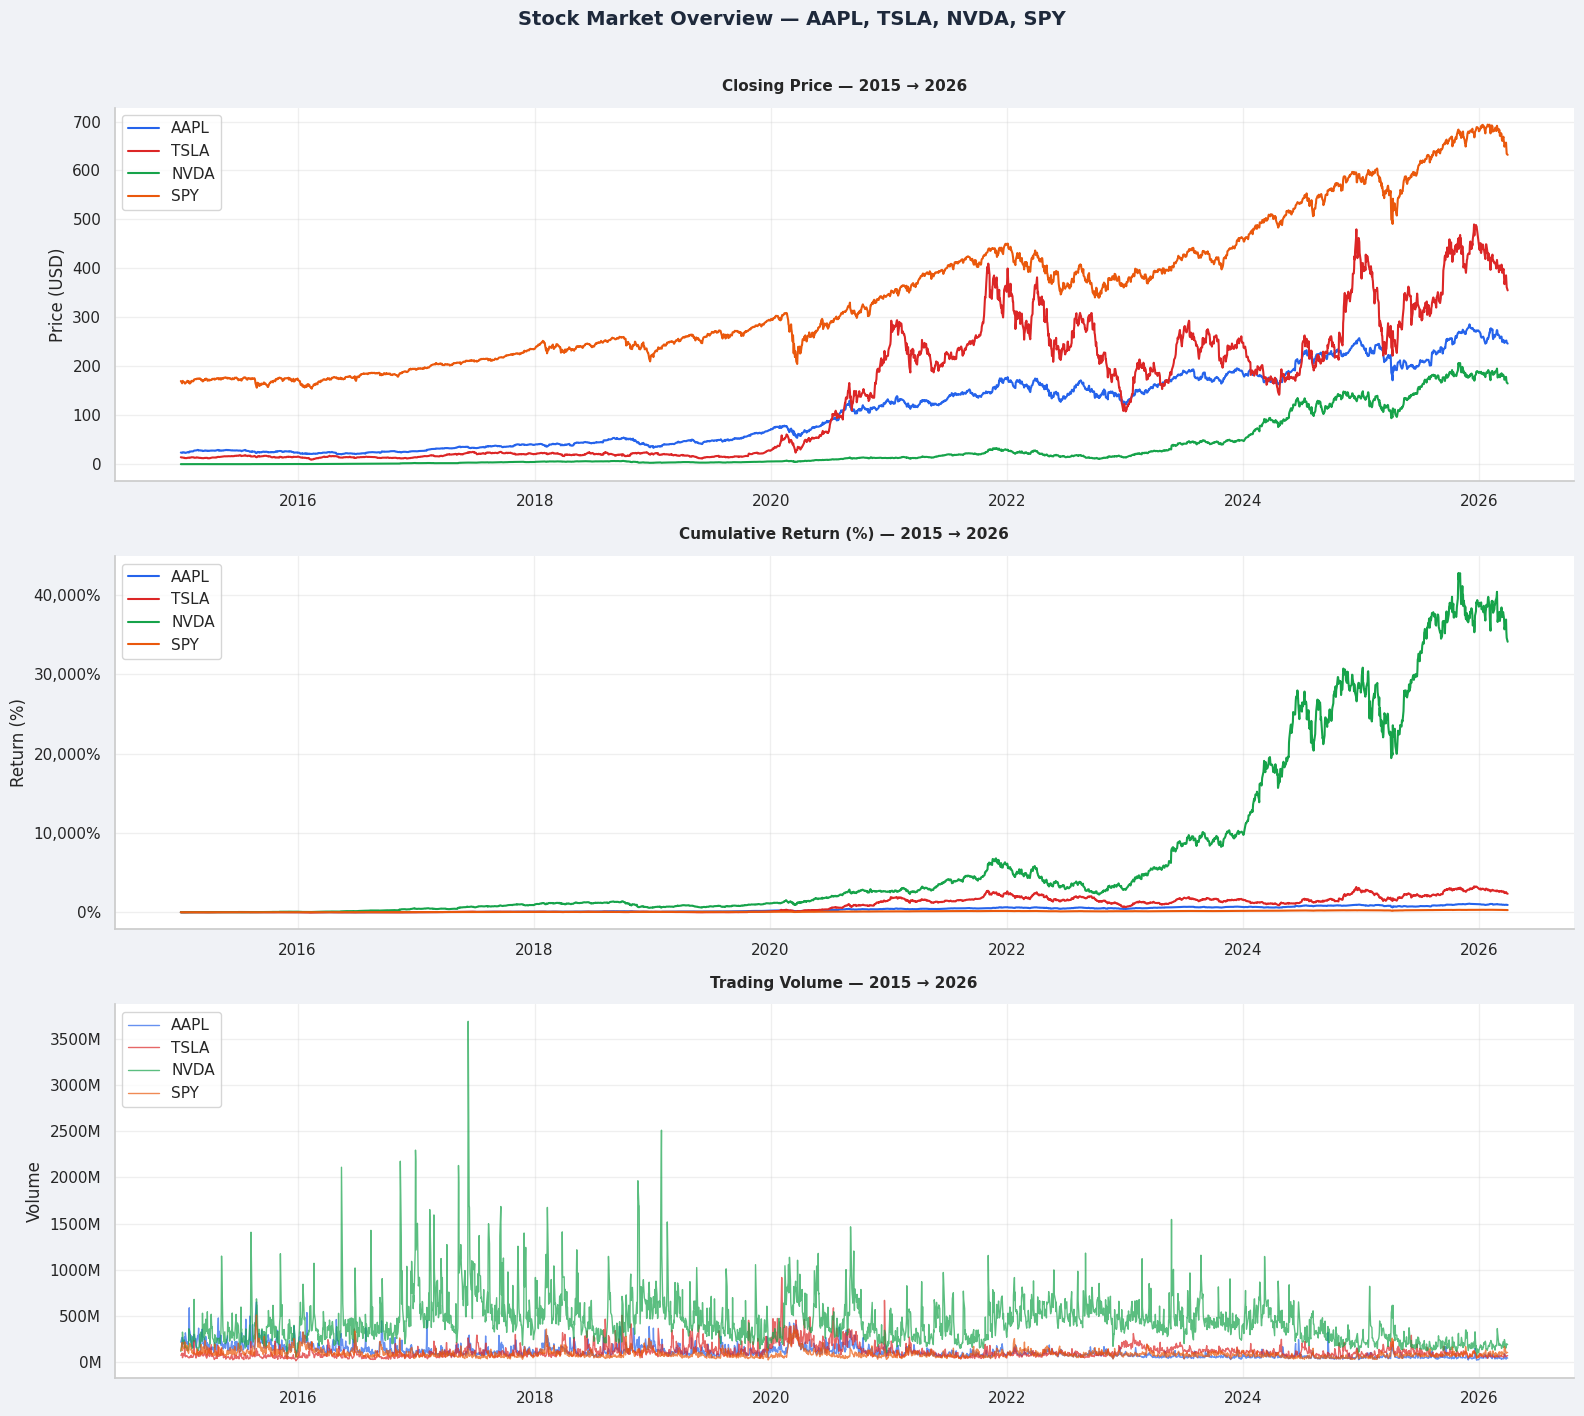

 Price evolution chart saved


In [5]:
# ==========================================================
# VISUALIZATION — Price Evolution + Volume
# ==========================================================

BG_COLOR   = "#f0f2f6"
CARD_COLOR = "#ffffff"
BLUE       = "#2563eb"
GREEN      = "#16a34a"
RED        = "#dc2626"
ORANGE     = "#ea580c"
PURPLE     = "#7c3aed"
GRAY       = "#6b7280"

TICKER_COLORS = {
    "AAPL": BLUE,
    "TSLA": RED,
    "NVDA": GREEN,
    "SPY" : ORANGE
}

plt.rcParams.update({
    "font.family"      : "DejaVu Sans",
    "axes.spines.top"  : False,
    "axes.spines.right": False,
    "axes.grid"        : True,
    "grid.alpha"       : 0.3,
    "axes.titlesize"   : 11,
    "axes.titleweight" : "bold",
    "axes.titlepad"    : 12,
})

fig, axes = plt.subplots(3, 1, figsize=(16, 14), facecolor=BG_COLOR)

# -------------------------
# Chart 1 — Closing Price
# -------------------------
ax1 = axes[0]
ax1.set_facecolor(CARD_COLOR)
for ticker, df in cleaned_data.items():
    ax1.plot(df.index, df["Close"],
             label=ticker,
             color=TICKER_COLORS[ticker],
             linewidth=1.5)
ax1.set_title("Closing Price — 2015 → 2026")
ax1.set_ylabel("Price (USD)")
ax1.legend(loc="upper left")
ax1.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

# -------------------------
# Chart 2 — Cumulative Return
# -------------------------
ax2 = axes[1]
ax2.set_facecolor(CARD_COLOR)
for ticker, df in cleaned_data.items():
    ax2.plot(df.index, df["Cumulative_Return"],
             label=ticker,
             color=TICKER_COLORS[ticker],
             linewidth=1.5)
ax2.set_title("Cumulative Return (%) — 2015 → 2026")
ax2.set_ylabel("Return (%)")
ax2.legend(loc="upper left")
ax2.yaxis.set_major_formatter(
    plt.FuncFormatter(lambda x, _: f"{x:,.0f}%"))
ax2.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

# -------------------------
# Chart 3 — Volume
# -------------------------
ax3 = axes[2]
ax3.set_facecolor(CARD_COLOR)
for ticker, df in cleaned_data.items():
    ax3.plot(df.index, df["Volume"],
             label=ticker,
             color=TICKER_COLORS[ticker],
             linewidth=1, alpha=0.7)
ax3.set_title("Trading Volume — 2015 → 2026")
ax3.set_ylabel("Volume")
ax3.legend(loc="upper left")
ax3.yaxis.set_major_formatter(
    plt.FuncFormatter(lambda x, _: f"{x/1e6:.0f}M"))
ax3.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

plt.suptitle(
    "Stock Market Overview — AAPL, TSLA, NVDA, SPY",
    fontsize=14, fontweight="bold", y=1.01, color="#1e293b"
)

plt.tight_layout()
plt.savefig("price_evolution.png", dpi=150,
            bbox_inches="tight", facecolor=BG_COLOR)
plt.show()

print(" Price evolution chart saved")
#print(" Preisdiagramm gespeichert")

> **Key insights:**

**Closing Price:**
- SPY dominates in absolute price — but it's an index of 500 companies
- NVDA and TSLA were nearly invisible before 2020 — then exploded
- COVID crash clearly visible in **March 2020** — all assets dropped sharply

**Cumulative Return:**
- NVDA's green line is **off the chart** — +34,097% makes all others invisible
- TSLA and AAPL look flat compared to NVDA — but still gained +2,330% and +918%
- SPY is the most stable — slow and steady +271%

**Trading Volume:**
- NVDA volume **exploded after 2023** — AI boom triggered massive trading activity
- Huge volume spike in **early 2020** — COVID panic selling
- AAPL, TSLA, SPY volumes relatively stable over time

##  Technical Indicators

Technical indicators help identify **trends, momentum and volatility** in stock prices.

| Indicator | Type | Description |
|-----------|------|-------------|
| **SMA** | Trend | Simple Moving Average — average price over N days |
| **EMA** | Trend | Exponential Moving Average — more weight on recent prices |
| **RSI** | Momentum | Relative Strength Index — overbought (>70) or oversold (<30) |
| **MACD** | Momentum | Moving Average Convergence Divergence — trend direction |
| **Bollinger Bands** | Volatility | Price channel — upper and lower bounds around SMA |

### Trading Signals
| Signal | Condition | Meaning |
|--------|-----------|---------|
| **Overbought** | RSI > 70 | Price may be too high — potential sell |
| **Oversold** | RSI < 30 | Price may be too low — potential buy |
| **Bullish Cross** | MACD > Signal | Upward momentum |
| **Bearish Cross** | MACD < Signal | Downward momentum |
| **Upper Band** | Price > Bollinger Upper | Potential reversal down |
| **Lower Band** | Price < Bollinger Lower | Potential reversal up |

In [6]:
# ==========================================================
# TECHNICAL INDICATORS
# ==========================================================

def add_technical_indicators(df):
    """
    Calculate and add technical indicators to a stock DataFrame.

    Indicators:
    - SMA 20, 50, 200 : Simple Moving Averages
    - EMA 20          : Exponential Moving Average
    - RSI 14          : Relative Strength Index
    - MACD            : Moving Average Convergence Divergence
    - Bollinger Bands : Upper, Middle, Lower bands
    """

    # -------------------------
    # 1. Simple Moving Averages
    # -------------------------
    df["SMA_20"]  = df["Close"].rolling(window=20).mean()
    df["SMA_50"]  = df["Close"].rolling(window=50).mean()
    df["SMA_200"] = df["Close"].rolling(window=200).mean()

    # -------------------------
    # 2. Exponential Moving Average
    # -------------------------
    df["EMA_20"] = df["Close"].ewm(span=20, adjust=False).mean()

    # -------------------------
    # 3. RSI (14 days)
    # -------------------------
    delta  = df["Close"].diff()
    gain   = delta.where(delta > 0, 0).rolling(window=14).mean()
    loss   = (-delta.where(delta < 0, 0)).rolling(window=14).mean()
    rs     = gain / loss
    df["RSI"] = 100 - (100 / (1 + rs))

    # -------------------------
    # 4. MACD
    # -------------------------
    ema_12      = df["Close"].ewm(span=12, adjust=False).mean()
    ema_26      = df["Close"].ewm(span=26, adjust=False).mean()
    df["MACD"]        = ema_12 - ema_26
    df["MACD_Signal"] = df["MACD"].ewm(span=9, adjust=False).mean()
    df["MACD_Hist"]   = df["MACD"] - df["MACD_Signal"]

    # -------------------------
    # 5. Bollinger Bands (20 days)
    # -------------------------
    df["BB_Middle"] = df["Close"].rolling(window=20).mean()
    df["BB_Std"]    = df["Close"].rolling(window=20).std()
    df["BB_Upper"]  = df["BB_Middle"] + (2 * df["BB_Std"])
    df["BB_Lower"]  = df["BB_Middle"] - (2 * df["BB_Std"])
    df["BB_Width"]  = (df["BB_Upper"] - df["BB_Lower"]) / df["BB_Middle"]

    return df

# Apply indicators to all tickers
for ticker in tickers:
    cleaned_data[ticker] = add_technical_indicators(cleaned_data[ticker])

# Output / Ausgabe
print(f" Technical indicators calculated for all tickers")
#print(f" Technische Indikatoren für alle Ticker berechnet")
print(f"\n{'Ticker':<8} {'Total Columns'}")
print("-" * 25)
for ticker, df in cleaned_data.items():
    print(f"{ticker:<8} {df.shape[1]}")

 Technical indicators calculated for all tickers

Ticker   Total Columns
-------------------------
AAPL     20
TSLA     20
NVDA     20
SPY      20


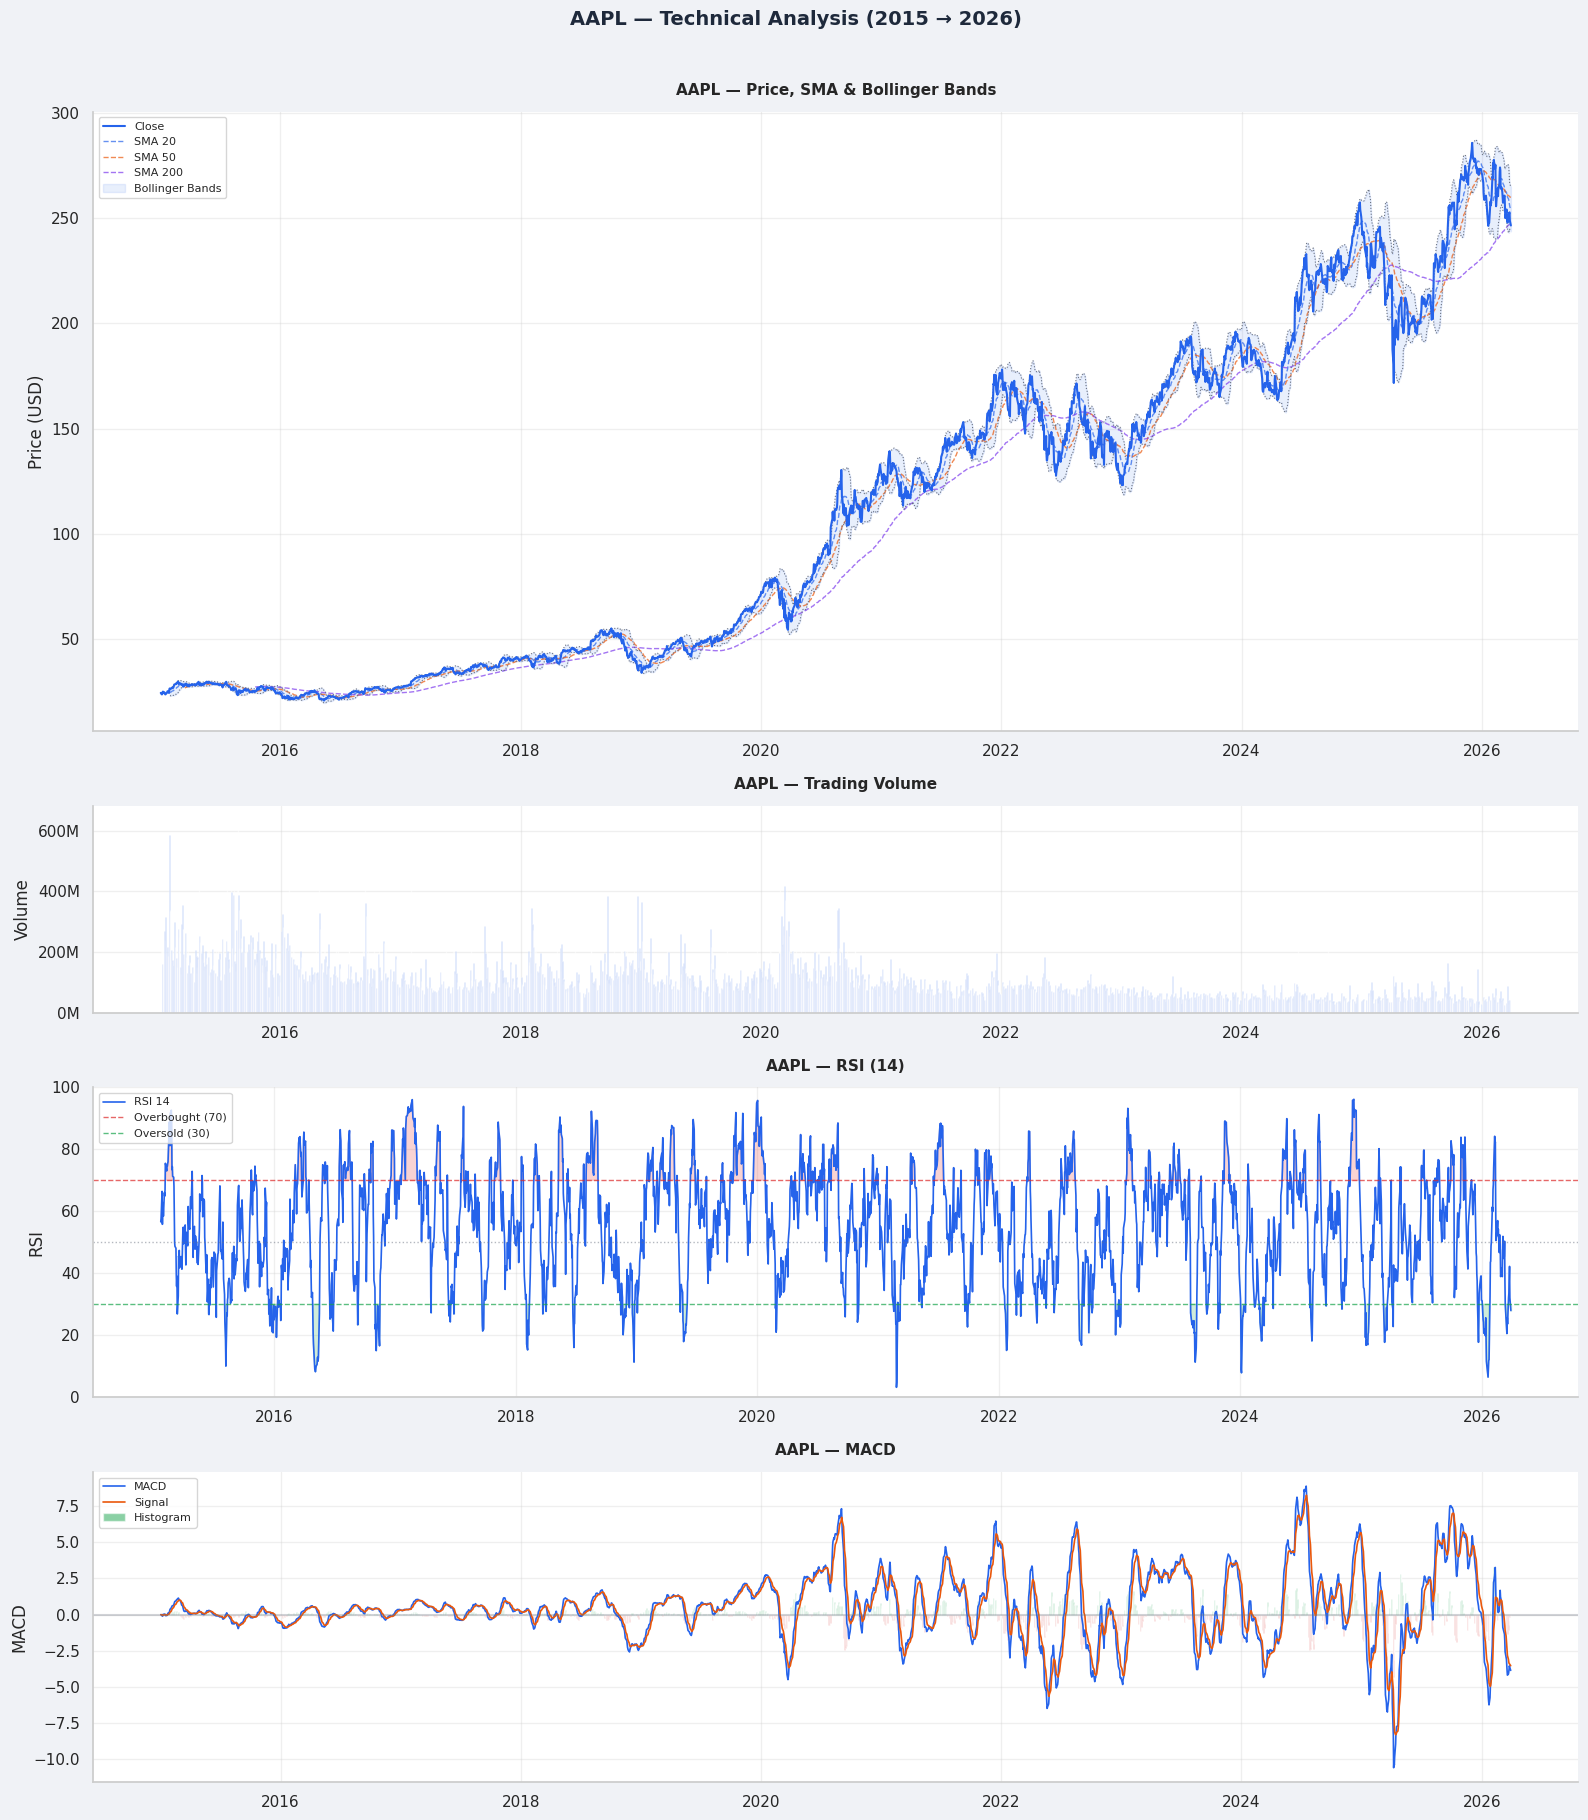

 AAPL technical chart saved


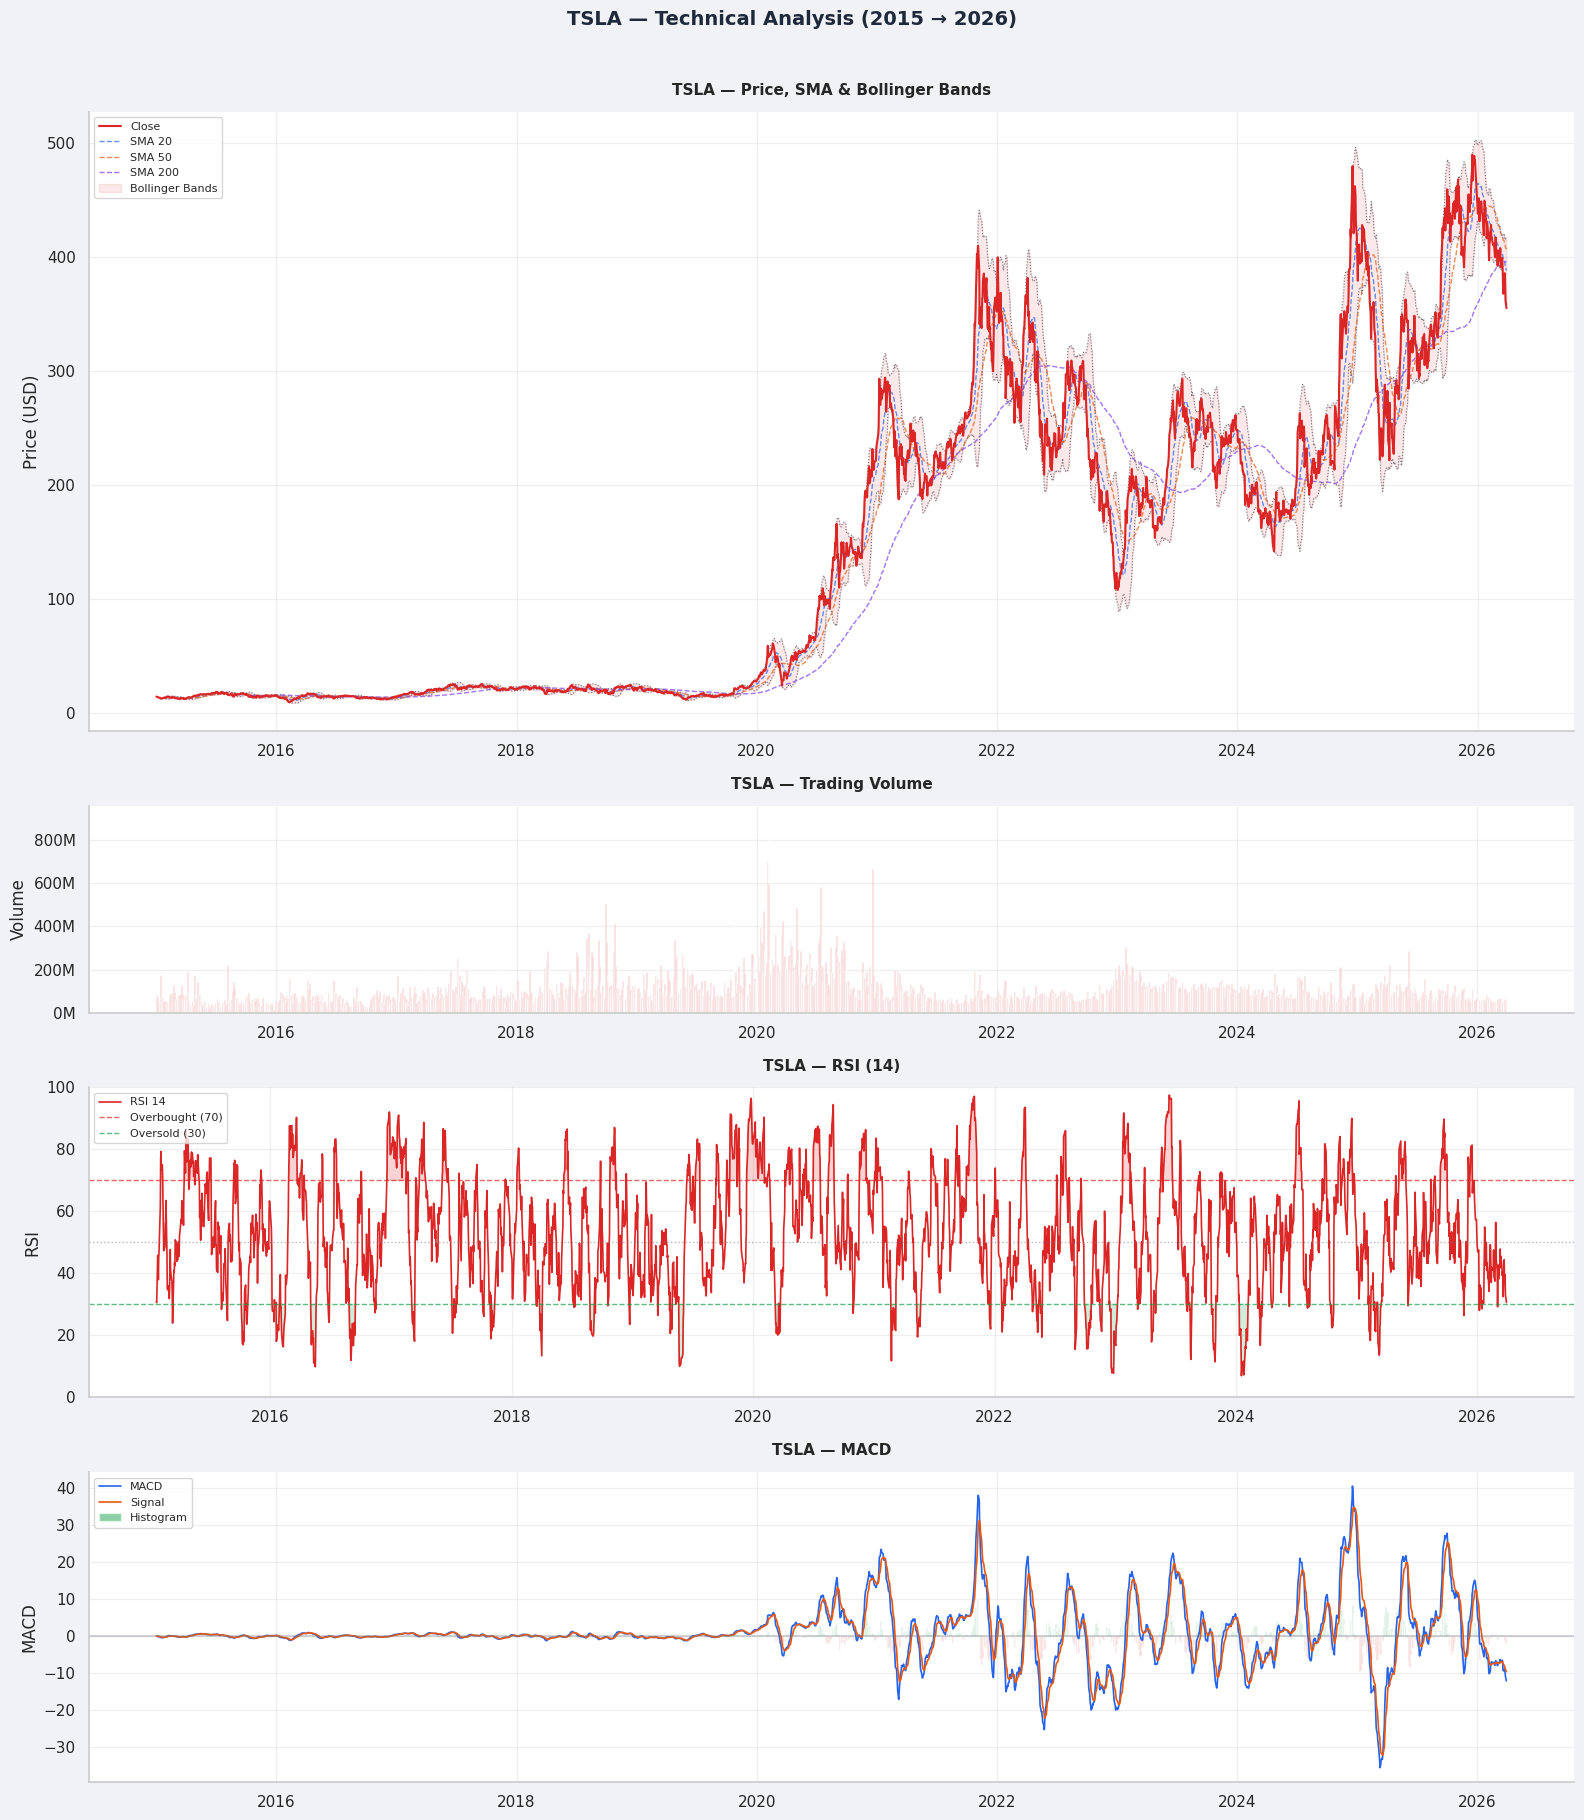

 TSLA technical chart saved


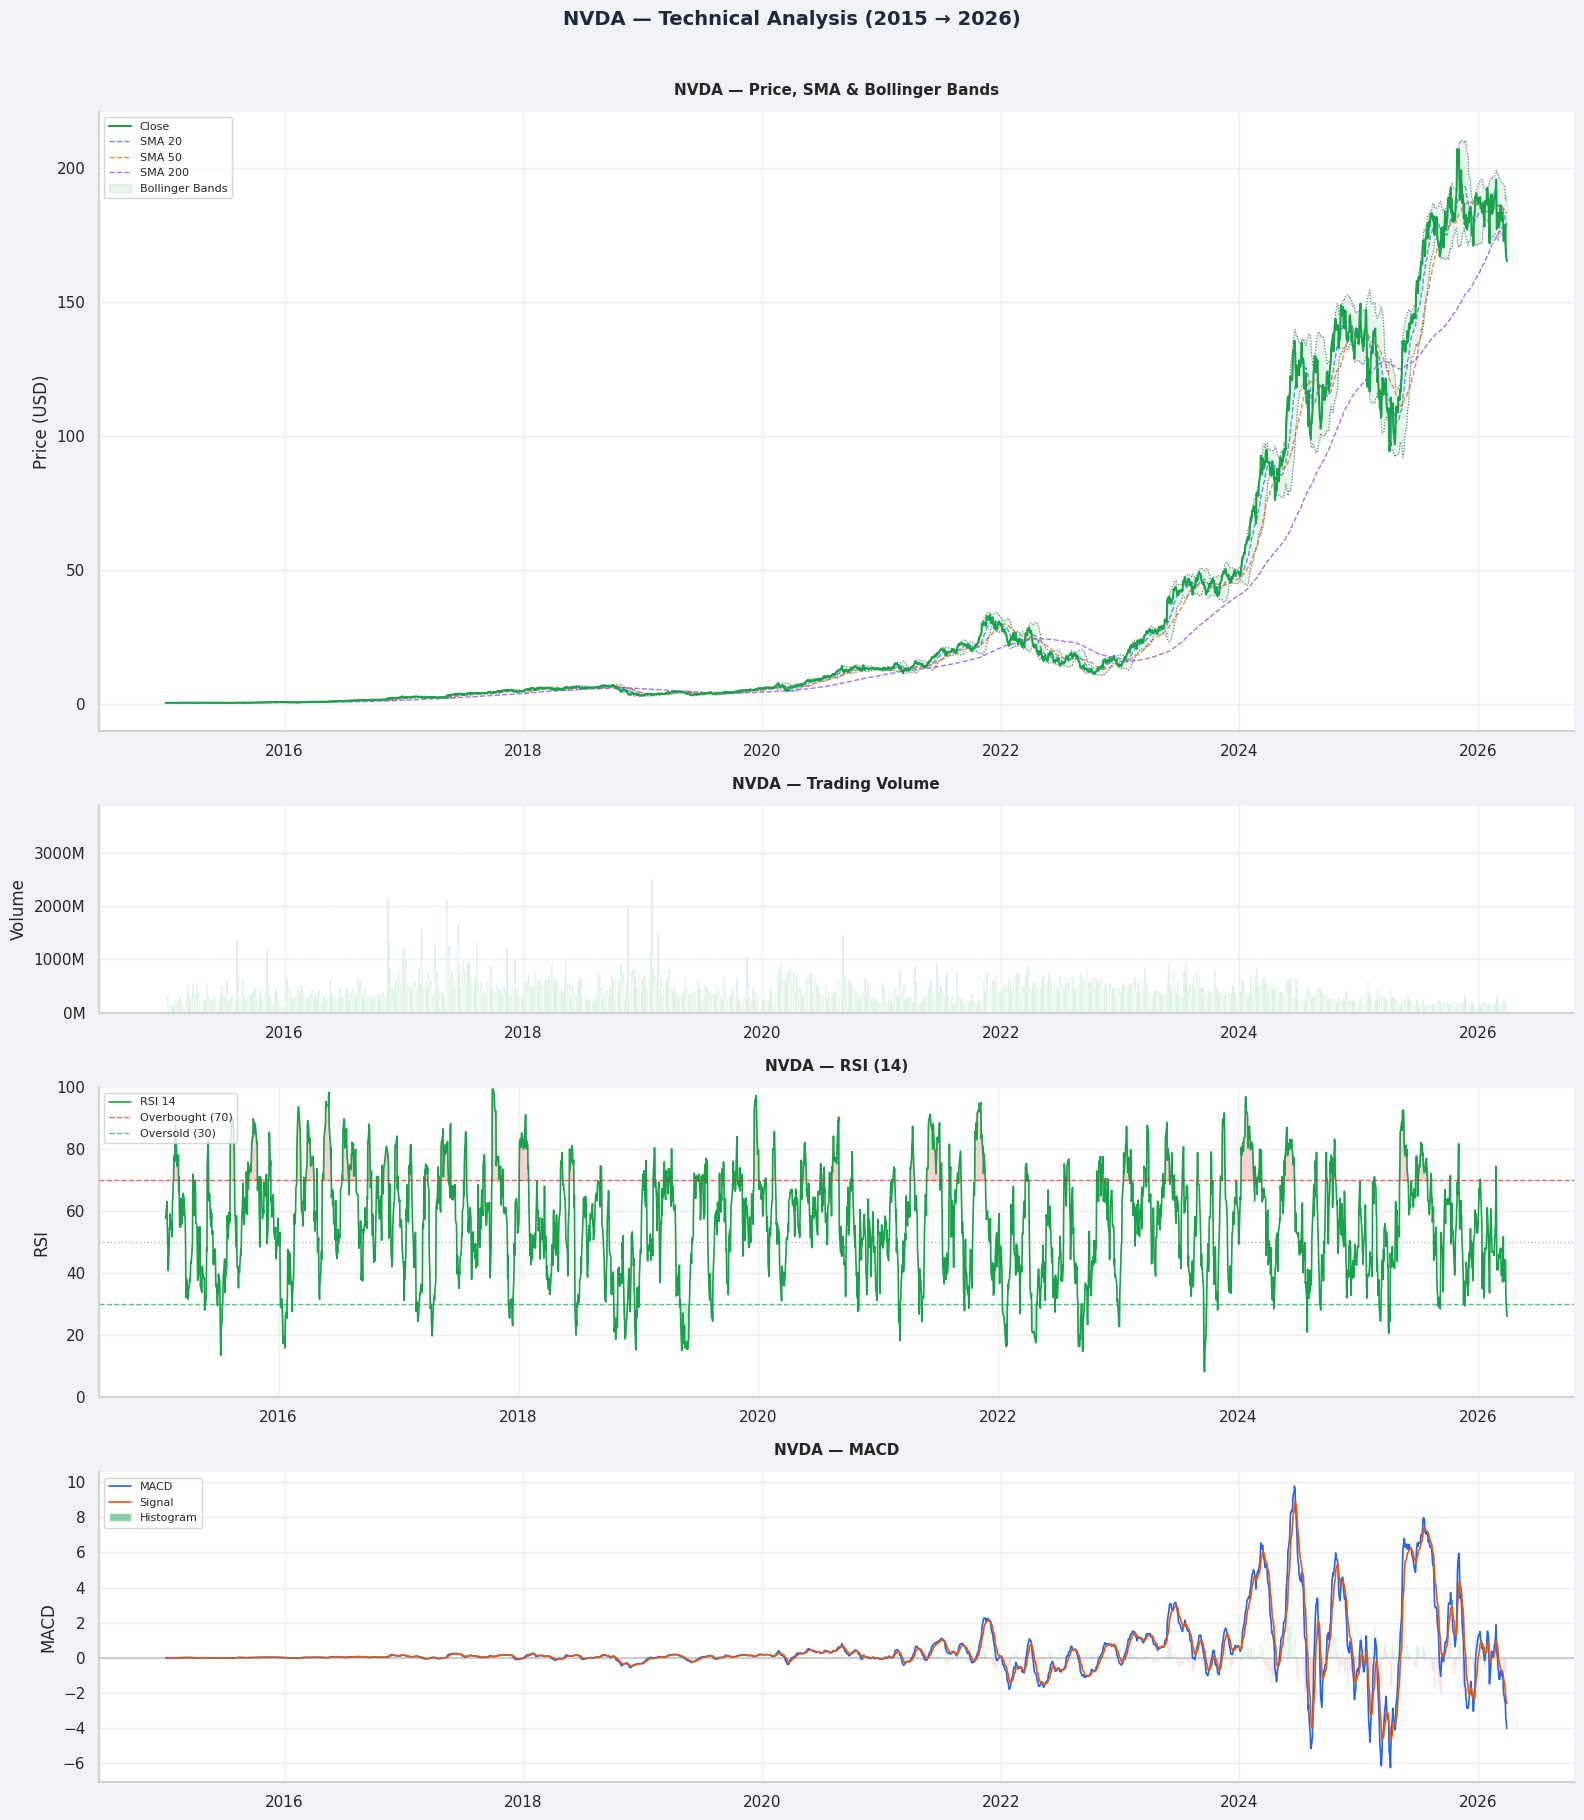

 NVDA technical chart saved


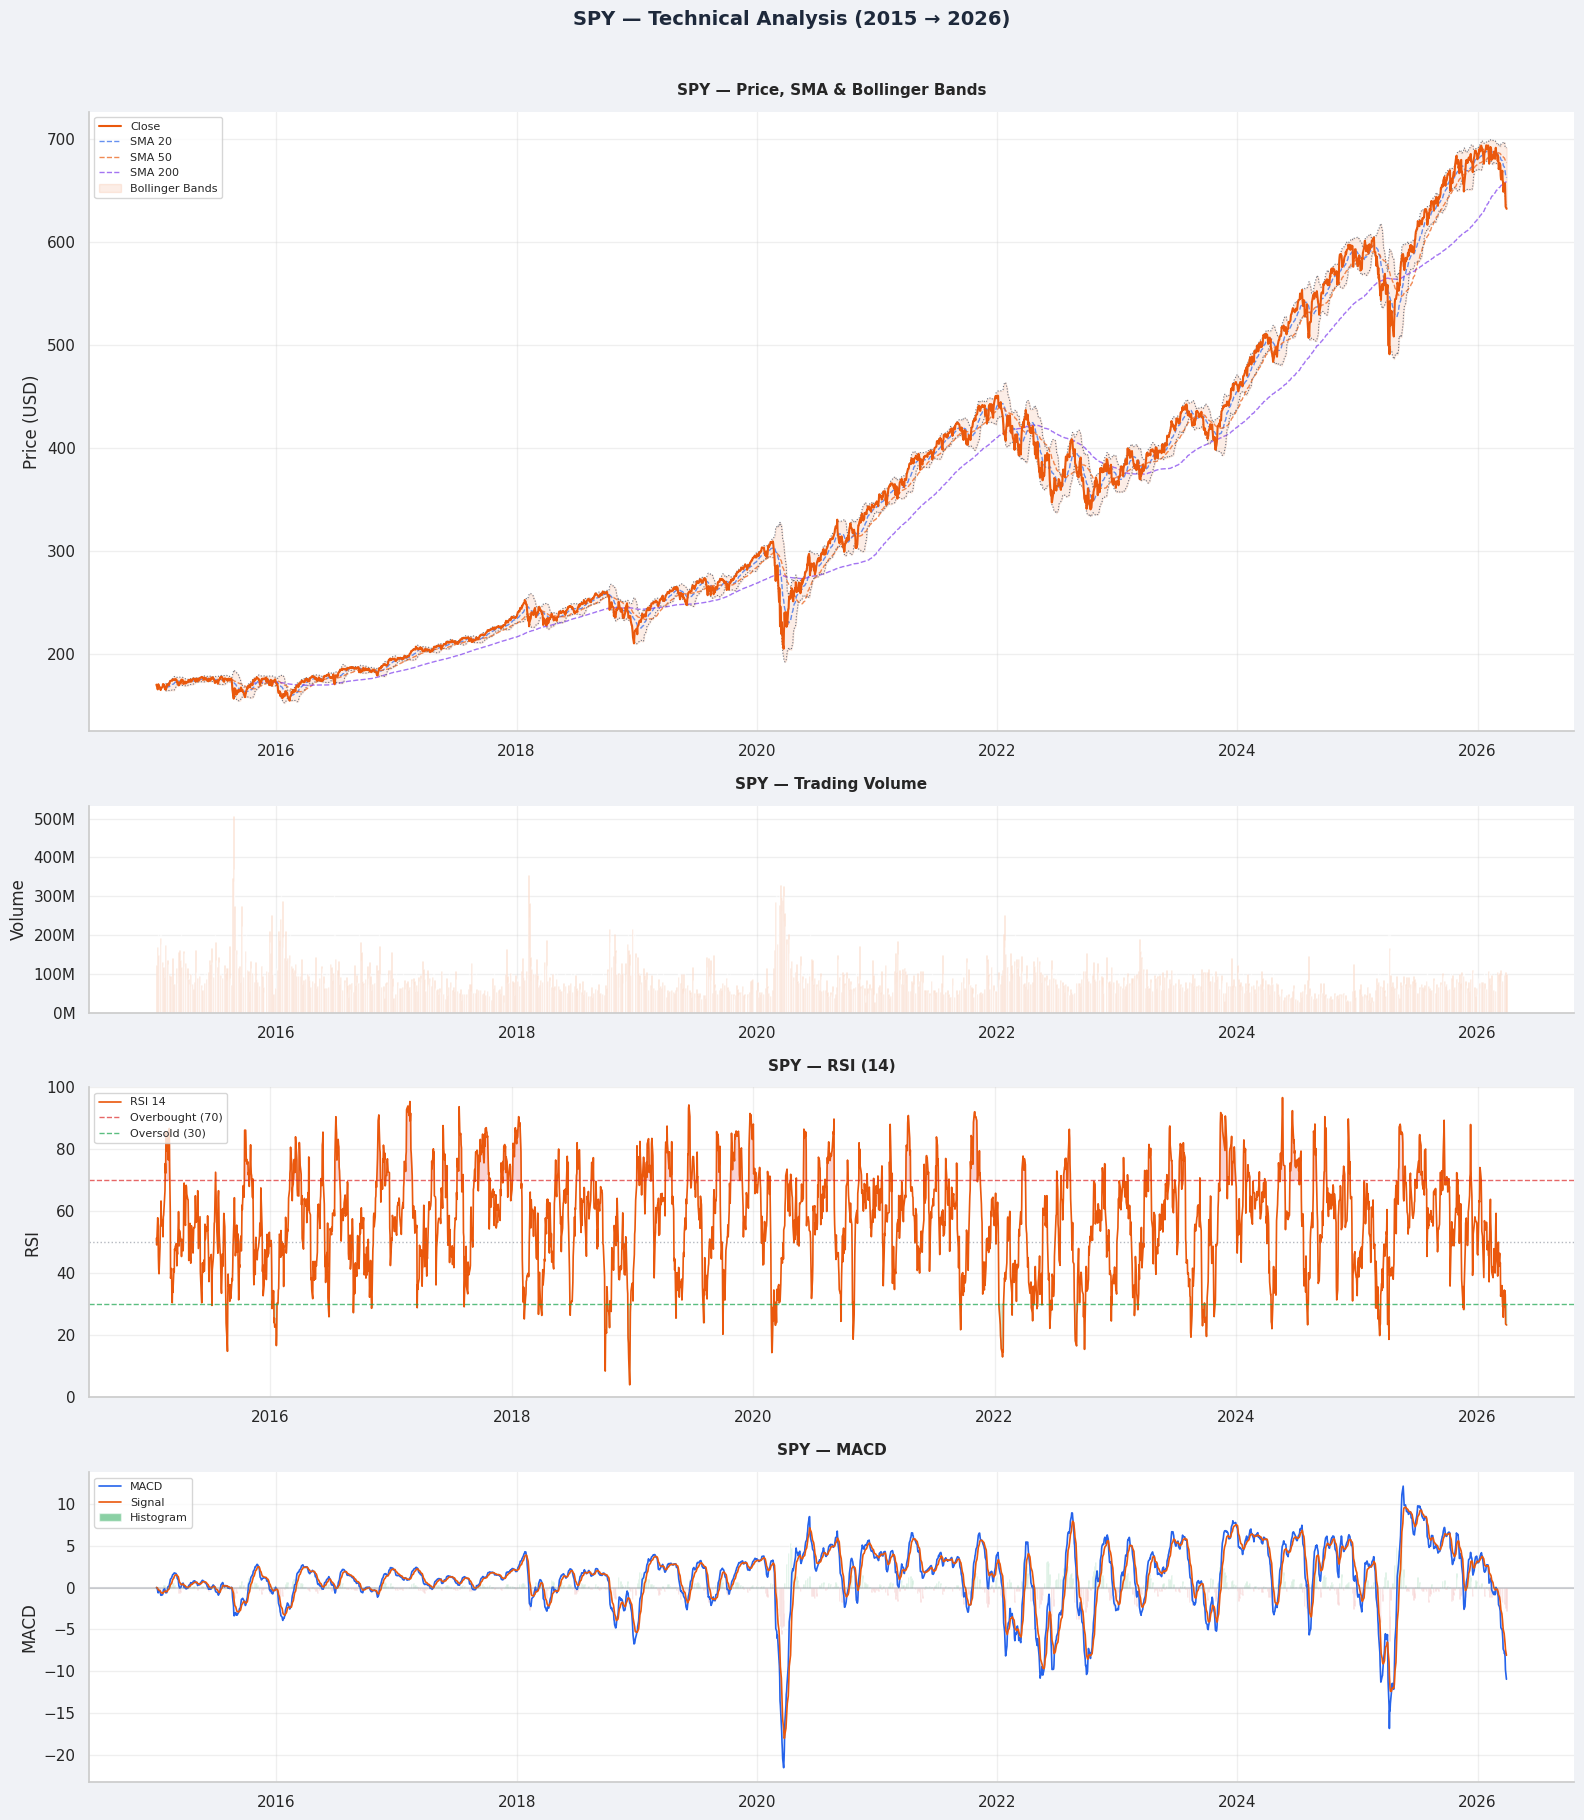

 SPY technical chart saved

 All technical charts saved


In [7]:
# ==========================================================
# VISUALIZATION — Technical Indicators
# ==========================================================

def plot_technical_indicators(ticker, df):
    """
    Plot 4 charts for a given ticker:
    1. Price + SMA + Bollinger Bands
    2. Volume
    3. RSI
    4. MACD
    """
    fig, axes = plt.subplots(4, 1, figsize=(16, 18),
                             facecolor=BG_COLOR,
                             gridspec_kw={"height_ratios": [3, 1, 1.5, 1.5]})

    color = TICKER_COLORS[ticker]

    # -------------------------
    # Chart 1 — Price + Indicators
    # -------------------------
    ax1 = axes[0]
    ax1.set_facecolor(CARD_COLOR)
    ax1.plot(df.index, df["Close"],
             color=color, linewidth=1.5, label="Close", zorder=3)
    ax1.plot(df.index, df["SMA_20"],
             color=BLUE, linewidth=1, linestyle="--",
             alpha=0.7, label="SMA 20")
    ax1.plot(df.index, df["SMA_50"],
             color=ORANGE, linewidth=1, linestyle="--",
             alpha=0.7, label="SMA 50")
    ax1.plot(df.index, df["SMA_200"],
             color=PURPLE, linewidth=1, linestyle="--",
             alpha=0.7, label="SMA 200")
    ax1.fill_between(df.index, df["BB_Upper"], df["BB_Lower"],
                     alpha=0.1, color=color, label="Bollinger Bands")
    ax1.plot(df.index, df["BB_Upper"],
             color=GRAY, linewidth=0.8, linestyle=":")
    ax1.plot(df.index, df["BB_Lower"],
             color=GRAY, linewidth=0.8, linestyle=":")
    ax1.set_title(f"{ticker} — Price, SMA & Bollinger Bands")
    ax1.set_ylabel("Price (USD)")
    ax1.legend(loc="upper left", fontsize=8)
    ax1.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

    # -------------------------
    # Chart 2 — Volume
    # -------------------------
    ax2 = axes[1]
    ax2.set_facecolor(CARD_COLOR)
    ax2.bar(df.index, df["Volume"],
            color=color, alpha=0.5, width=1)
    ax2.set_title(f"{ticker} — Trading Volume")
    ax2.set_ylabel("Volume")
    ax2.yaxis.set_major_formatter(
        plt.FuncFormatter(lambda x, _: f"{x/1e6:.0f}M"))
    ax2.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

    # -------------------------
    # Chart 3 — RSI
    # -------------------------
    ax3 = axes[2]
    ax3.set_facecolor(CARD_COLOR)
    ax3.plot(df.index, df["RSI"],
             color=color, linewidth=1.2, label="RSI 14")
    ax3.axhline(y=70, color=RED,   linestyle="--",
                alpha=0.7, linewidth=1, label="Overbought (70)")
    ax3.axhline(y=30, color=GREEN, linestyle="--",
                alpha=0.7, linewidth=1, label="Oversold (30)")
    ax3.axhline(y=50, color=GRAY,  linestyle=":",
                alpha=0.5, linewidth=1)
    ax3.fill_between(df.index, df["RSI"], 70,
                     where=(df["RSI"] >= 70),
                     alpha=0.2, color=RED)
    ax3.fill_between(df.index, df["RSI"], 30,
                     where=(df["RSI"] <= 30),
                     alpha=0.2, color=GREEN)
    ax3.set_ylim(0, 100)
    ax3.set_title(f"{ticker} — RSI (14)")
    ax3.set_ylabel("RSI")
    ax3.legend(loc="upper left", fontsize=8)
    ax3.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

    # -------------------------
    # Chart 4 — MACD
    # -------------------------
    ax4 = axes[3]
    ax4.set_facecolor(CARD_COLOR)
    ax4.plot(df.index, df["MACD"],
             color=BLUE, linewidth=1.2, label="MACD")
    ax4.plot(df.index, df["MACD_Signal"],
             color=ORANGE, linewidth=1.2, label="Signal")
    ax4.bar(df.index, df["MACD_Hist"],
            color=[GREEN if v >= 0 else RED for v in df["MACD_Hist"]],
            alpha=0.5, width=1, label="Histogram")
    ax4.axhline(y=0, color=GRAY, linestyle="-", alpha=0.3)
    ax4.set_title(f"{ticker} — MACD")
    ax4.set_ylabel("MACD")
    ax4.legend(loc="upper left", fontsize=8)
    ax4.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

    plt.suptitle(
        f"{ticker} — Technical Analysis (2015 → 2026)",
        fontsize=14, fontweight="bold", y=1.01, color="#1e293b"
    )

    plt.tight_layout()
    plt.savefig(f"technical_{ticker.lower()}.png",
                dpi=150, bbox_inches="tight", facecolor=BG_COLOR)
    plt.show()
    print(f" {ticker} technical chart saved")

# Plot for all tickers
for ticker in tickers:
    plot_technical_indicators(ticker, cleaned_data[ticker])

print(f"\n All technical charts saved")
#print(f" Alle technischen Charts gespeichert")

### Technical Indicators Results

#### AAPL — Apple
> - Price consistently **above all SMAs** — strong uptrend
> - RSI frequently hits **overbought (70+)** — high demand
> - MACD shows **regular bullish/bearish cycles** — stable volatility

#### TSLA — Tesla
> - Price was **flat until 2020** then exploded — COVID catalyst
> - RSI extremely volatile — **overbought in 2021, oversold in 2022**
> - MACD shows **massive swings** — highest volatility of all 4 assets

#### NVDA — Nvidia
> - Price nearly invisible until **2023 AI boom** — then vertical
> - RSI consistently **above 50** since 2023 — relentless buying pressure
> - MACD **exploded in 2023-2024** — strongest momentum of all assets

#### SPY — S&P 500
> - Smoothest price curve — **500 companies average out volatility**
> - RSI **crashed to 10 in March 2020** — extreme COVID panic
> - MACD shows **clear COVID crash and recovery** signal in 2020

>  **Key insight:** TSLA has the highest volatility,
> NVDA has the strongest recent momentum,
> SPY is the most stable and predictable asset.

## COVID Impact Analysis

We analyze the impact of the COVID-19 crash on each asset.

### Key Dates
| Event | Date |
|-------|------|
| WHO declares pandemic | March 11, 2020 |
| Market bottom | March 23, 2020 |
| Full recovery | August 2020 |

### What we measure
- **Peak before crash** — highest price before COVID
- **Bottom of crash** — lowest price during COVID
- **Max drawdown** — % drop from peak to bottom
- **Recovery time** — days to recover previous high
- **1 year after crash** — performance 12 months later

COVID-19 IMPACT ANALYSIS
Ticker      Pre-COVID       Bottom   Drawdown     Recovery     1Y After
----------------------------------------------------------------------
AAPL     $      79.06 $      54.21     -31.4% $     119.35      120.2%
TSLA     $      61.16 $      24.08     -60.6% $     220.72      816.6%
NVDA     $       7.83 $       4.89     -37.6% $      13.04      166.6%
SPY      $     309.20 $     204.94     -33.7% $     363.79       77.5%


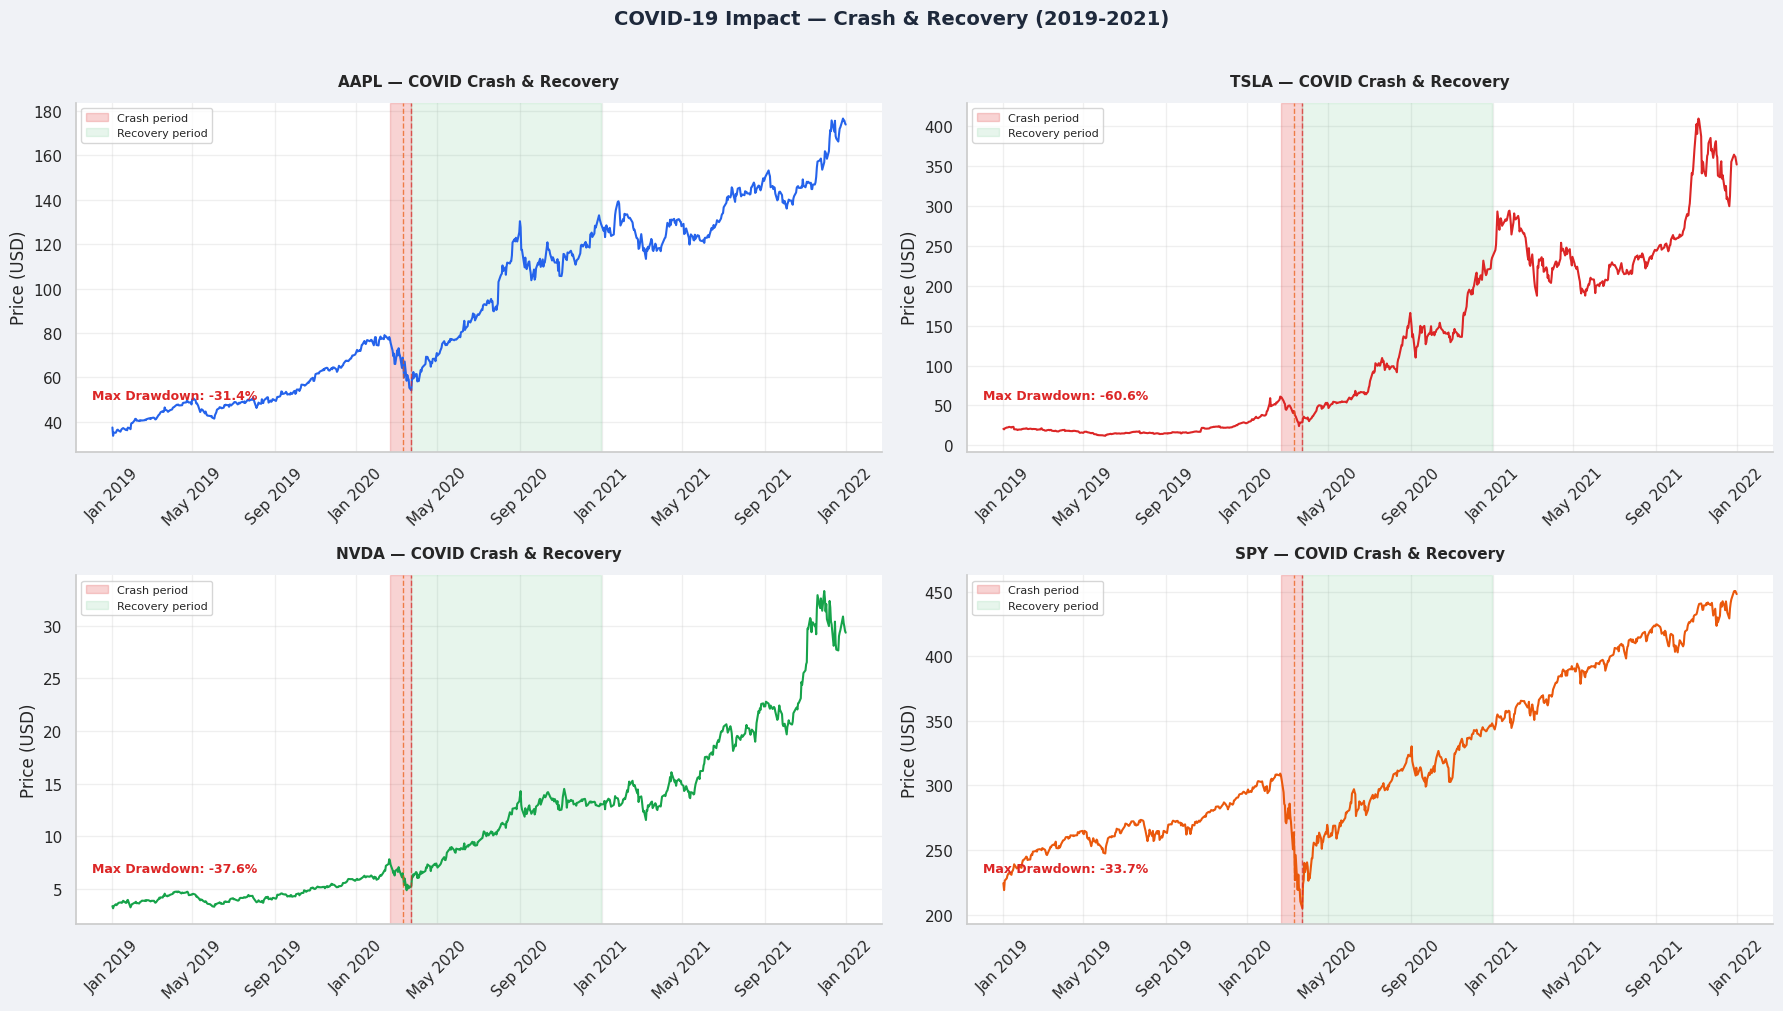


 COVID impact chart saved


In [8]:
# ==========================================================
# COVID IMPACT ANALYSIS
# ==========================================================

# Key dates
covid_start    = "2020-01-01"
covid_crash    = "2020-03-23"
covid_recovery = "2020-12-31"
one_year_after = "2021-03-23"

print("COVID-19 IMPACT ANALYSIS")
print("=" * 70)
print(f"{'Ticker':<8} {'Pre-COVID':>12} {'Bottom':>12} "
      f"{'Drawdown':>10} {'Recovery':>12} {'1Y After':>12}")
print("-" * 70)

covid_data = {}

for ticker, df in cleaned_data.items():
    # Peak before crash (Jan - Feb 2020)
    pre_covid  = df.loc["2020-01-01":"2020-02-19", "Close"].max()

    # Bottom of crash
    bottom     = df.loc["2020-02-20":"2020-03-23", "Close"].min()

    # Max drawdown
    drawdown   = ((bottom - pre_covid) / pre_covid) * 100

    # Price at 1 year after crash
    one_year   = df.loc[one_year_after, "Close"]

    # Return from bottom to 1 year after
    recovery   = ((one_year - bottom) / bottom) * 100

    covid_data[ticker] = {
        "pre_covid" : pre_covid,
        "bottom"    : bottom,
        "drawdown"  : drawdown,
        "one_year"  : one_year,
        "recovery"  : recovery
    }

    print(f"{ticker:<8} ${pre_covid:>11.2f} ${bottom:>11.2f} "
          f"{drawdown:>9.1f}% ${one_year:>11.2f} "
          f"{recovery:>10.1f}%")

# -------------------------
# Plot COVID crash period
# -------------------------
fig, axes = plt.subplots(2, 2, figsize=(18, 10), facecolor=BG_COLOR)
axes = axes.flatten()

for i, (ticker, df) in enumerate(cleaned_data.items()):
    ax = axes[i]
    ax.set_facecolor(CARD_COLOR)

    # Plot price 2019-2021
    mask = (df.index >= "2019-01-01") & (df.index <= "2021-12-31")
    df_plot = df[mask]

    ax.plot(df_plot.index, df_plot["Close"],
            color=TICKER_COLORS[ticker], linewidth=1.5)

    # Highlight crash period
    ax.axvspan(pd.Timestamp("2020-02-20"),
               pd.Timestamp("2020-03-23"),
               alpha=0.2, color=RED, label="Crash period")

    # Highlight recovery period
    ax.axvspan(pd.Timestamp("2020-03-23"),
               pd.Timestamp("2020-12-31"),
               alpha=0.1, color=GREEN, label="Recovery period")

    # Annotations
    ax.axvline(pd.Timestamp("2020-03-23"),
               color=RED, linestyle="--", alpha=0.7, linewidth=1)
    ax.axvline(pd.Timestamp("2020-03-11"),
               color=ORANGE, linestyle="--", alpha=0.7, linewidth=1)

    ax.set_title(f"{ticker} — COVID Crash & Recovery")
    ax.set_ylabel("Price (USD)")
    ax.legend(loc="upper left", fontsize=8)
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
    ax.tick_params(axis="x", rotation=45)

    # Add drawdown text
    dd = covid_data[ticker]["drawdown"]
    ax.text(0.02, 0.15,
            f"Max Drawdown: {dd:.1f}%",
            transform=ax.transAxes,
            fontsize=9, color=RED, fontweight="bold")

plt.suptitle(
    "COVID-19 Impact — Crash & Recovery (2019-2021)",
    fontsize=14, fontweight="bold", y=1.01, color="#1e293b"
)

plt.tight_layout()
plt.savefig("covid_impact.png", dpi=150,
            bbox_inches="tight", facecolor=BG_COLOR)
plt.show()

print(f"\n COVID impact chart saved")
#print(f" COVID-Auswirkungsdiagramm gespeichert")

>  **Key insights:**
> - **TSLA was the hardest hit** — dropped -60.6% but recovered +816.6% 
> in just 12 months — the most spectacular recovery in this dataset
> - **AAPL was the most resilient** — smallest drawdown (-31.4%) 
> and strong recovery (+120.2%)
> - **SPY recovered the slowest** (+77.5%) — 500 companies 
> average out both the crash and the recovery
> - **All 4 assets fully recovered within 12 months** — 
> confirming that COVID was a short-term shock, not a structural crisis

## Correlation Analysis

We measure how closely the assets move together.

### Correlation Scale
| Value | Interpretation |
|-------|----------------|
| **+1.0** | Perfect positive correlation — move together |
| **+0.7 to +1.0** | Strong positive correlation |
| **0.0** | No correlation |
| **-0.7 to -1.0** | Strong negative correlation — move oppositely |
| **-1.0** | Perfect negative correlation |

### What we analyze
- **Daily returns correlation** — short term relationship
- **Price correlation** — long term relationship
- **Rolling correlation** — how correlation changes over time

DAILY RETURNS CORRELATION
---------------------------------------------
      AAPL  TSLA  NVDA  SPY
AAPL  1.00  0.43  0.53 0.74
TSLA  0.43  1.00  0.41 0.49
NVDA  0.53  0.41  1.00 0.65
SPY   0.74  0.49  0.65 1.00

PRICE CORRELATION
---------------------------------------------
      AAPL  TSLA  NVDA  SPY
AAPL  1.00  0.94  0.85 0.98
TSLA  0.94  1.00  0.76 0.92
NVDA  0.85  0.76  1.00 0.91
SPY   0.98  0.92  0.91 1.00


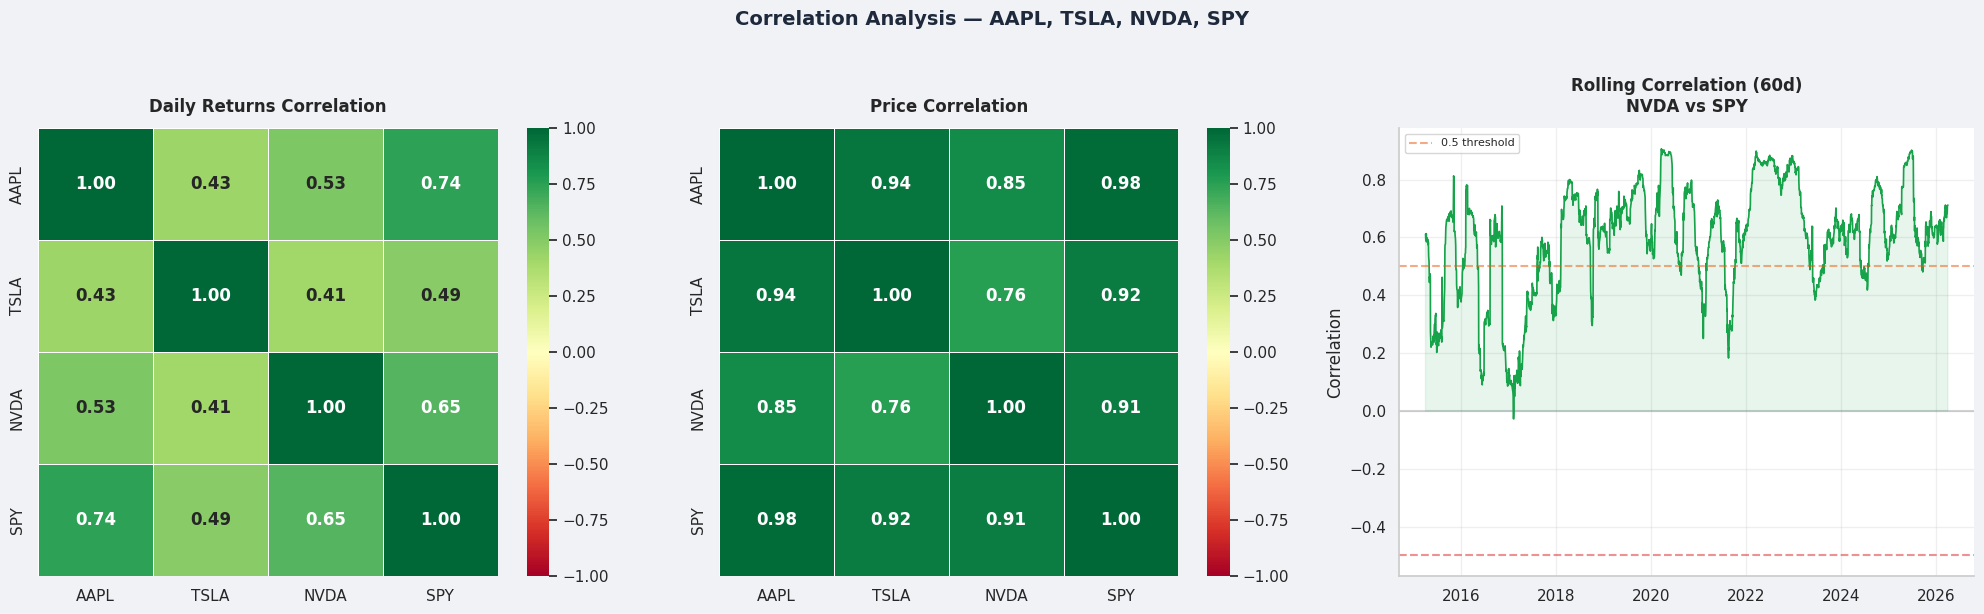

 Correlation analysis saved


In [9]:
# ==========================================================
# CORRELATION ANALYSIS
# ==========================================================

# -------------------------
# 1. Build returns matrix
# -------------------------
returns_df = pd.DataFrame({
    ticker: cleaned_data[ticker]["Daily_Return"]
    for ticker in tickers
}).dropna()

price_df = pd.DataFrame({
    ticker: cleaned_data[ticker]["Close"]
    for ticker in tickers
}).dropna()

# -------------------------
# 2. Correlation matrices
# -------------------------
returns_corr = returns_df.corr().round(3)
price_corr   = price_df.corr().round(3)

print("DAILY RETURNS CORRELATION")
print("-" * 45)
print(returns_corr.to_string())

print("\nPRICE CORRELATION")
print("-" * 45)
print(price_corr.to_string())

# -------------------------
# 3. Plot
# -------------------------
fig, axes = plt.subplots(1, 3, figsize=(20, 6), facecolor=BG_COLOR)

# Heatmap 1 — Returns correlation
ax1 = axes[0]
ax1.set_facecolor(CARD_COLOR)
sns.heatmap(
    returns_corr,
    annot=True, fmt=".2f",
    cmap="RdYlGn",
    vmin=-1, vmax=1,
    ax=ax1,
    linewidths=0.5,
    annot_kws={"size": 12, "weight": "bold"}
)
ax1.set_title("Daily Returns Correlation", fontsize=12, fontweight="bold")

# Heatmap 2 — Price correlation
ax2 = axes[1]
ax2.set_facecolor(CARD_COLOR)
sns.heatmap(
    price_corr,
    annot=True, fmt=".2f",
    cmap="RdYlGn",
    vmin=-1, vmax=1,
    ax=ax2,
    linewidths=0.5,
    annot_kws={"size": 12, "weight": "bold"}
)
ax2.set_title("Price Correlation", fontsize=12, fontweight="bold")

# Rolling correlation — NVDA vs SPY
ax3 = axes[2]
ax3.set_facecolor(CARD_COLOR)
rolling_corr = (
    returns_df["NVDA"]
    .rolling(window=60)
    .corr(returns_df["SPY"])
)
ax3.plot(rolling_corr.index, rolling_corr,
         color=GREEN, linewidth=1.2)
ax3.axhline(y=0,    color=GRAY, linestyle="-",  alpha=0.3)
ax3.axhline(y=0.5,  color=ORANGE, linestyle="--", alpha=0.5,
            label="0.5 threshold")
ax3.axhline(y=-0.5, color=RED, linestyle="--", alpha=0.5)
ax3.fill_between(rolling_corr.index, rolling_corr, 0,
                 where=(rolling_corr >= 0),
                 alpha=0.1, color=GREEN)
ax3.fill_between(rolling_corr.index, rolling_corr, 0,
                 where=(rolling_corr < 0),
                 alpha=0.1, color=RED)
ax3.set_title("Rolling Correlation (60d)\nNVDA vs SPY",
              fontsize=12, fontweight="bold")
ax3.set_ylabel("Correlation")
ax3.legend(fontsize=8)
ax3.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

plt.suptitle(
    "Correlation Analysis — AAPL, TSLA, NVDA, SPY",
    fontsize=14, fontweight="bold", y=1.02, color="#1e293b"
)

plt.tight_layout()
plt.savefig("correlation_analysis.png", dpi=150,
            bbox_inches="tight", facecolor=BG_COLOR)
plt.show()

print(" Correlation analysis saved")
#print(" Korrelationsanalyse gespeichert")

>  **Key insights:**
> - **Price correlation is very high (0.76-0.98)** — all assets 
> trended upward together over 10 years
> - **Daily returns correlation is much lower (0.41-0.74)** — 
> day-to-day movements are more independent
> - **AAPL is the most correlated with SPY (0.74)** — 
> Apple essentially moves with the market
> - **TSLA is the least correlated (0.41-0.49)** — 
> Tesla moves independently — driven by its own news
> - **Important distinction:** high price correlation does NOT mean 
> the stocks move together daily — it just means they all went up over time

##  Volatility Analysis

Volatility measures the **risk** of an asset — how much the price fluctuates.

### Metrics
| Metric | Formula | Description |
|--------|---------|-------------|
| **Daily Volatility** | `std(Daily_Return)` | Day-to-day price fluctuation |
| **Annual Volatility** | `Daily_Vol × √252` | Annualized risk (252 trading days) |
| **Rolling Volatility** | `std(30d window)` | How volatility changes over time |
| **Sharpe Ratio** | `Return / Volatility` | Risk-adjusted performance |
| **Max Drawdown** | `(Peak - Trough) / Peak` | Worst peak-to-trough loss |

### Risk vs Return
> A good investment maximizes **return per unit of risk**
> — measured by the **Sharpe Ratio**

VOLATILITY ANALYSIS
Ticker    Daily Vol   Annual Vol   Total Return     Sharpe   Max Drawdown
---------------------------------------------------------------------------
AAPL          1.81%       28.76%         918.5%       0.86         -38.5%
TSLA          3.61%       57.37%        2330.0%       0.78         -73.6%
NVDA          3.05%       48.45%       34097.7%       1.32         -66.3%
SPY           1.12%       17.71%         271.5%       0.75         -33.7%


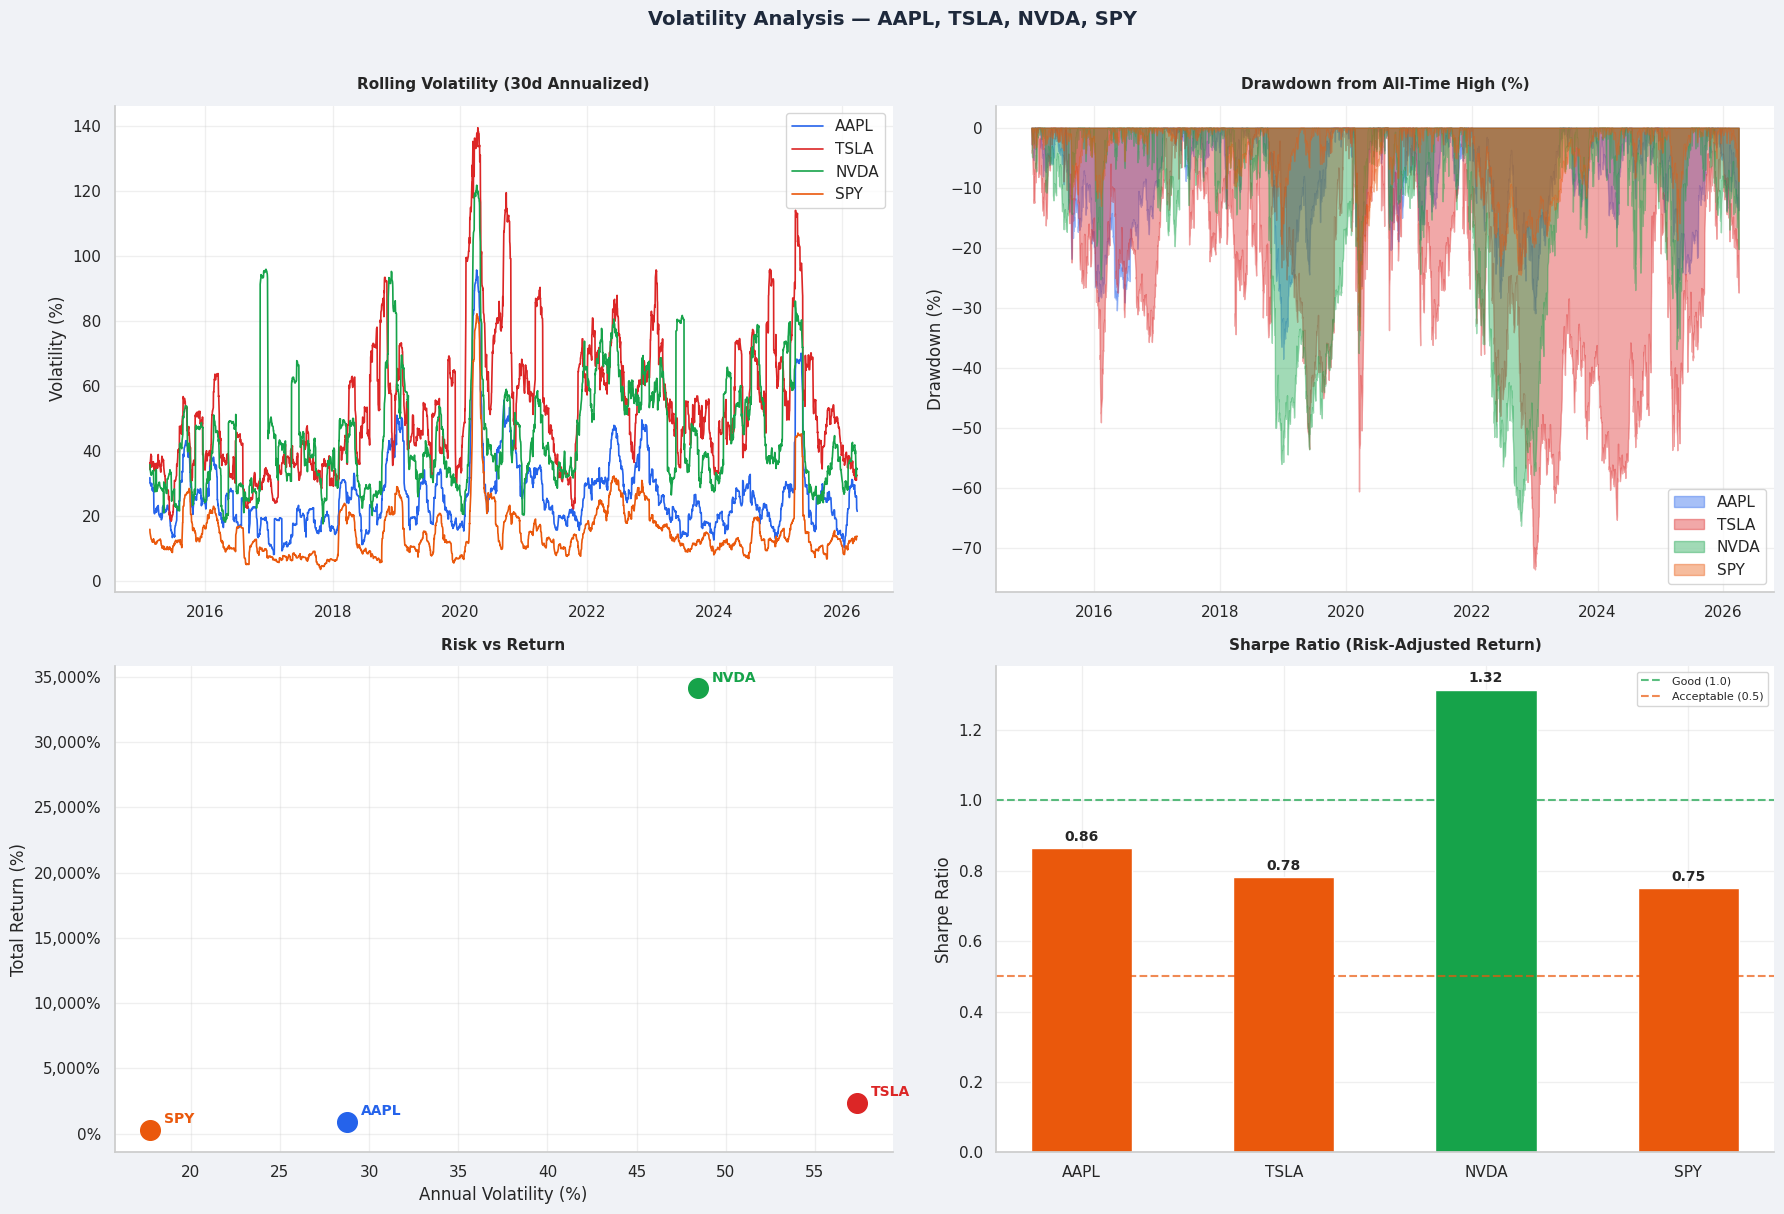

 Volatility analysis saved


In [10]:
# ==========================================================
# VOLATILITY ANALYSIS
# ==========================================================

# -------------------------
# 1. Volatility metrics
# -------------------------
print("VOLATILITY ANALYSIS")
print("=" * 75)
print(f"{'Ticker':<8} {'Daily Vol':>10} {'Annual Vol':>12} "
      f"{'Total Return':>14} {'Sharpe':>10} {'Max Drawdown':>14}")
print("-" * 75)

volatility_data = {}

for ticker, df in cleaned_data.items():
    # Daily volatility
    daily_vol  = df["Daily_Return"].std()

    # Annual volatility
    annual_vol = daily_vol * np.sqrt(252)

    # Total return
    total_ret  = df["Cumulative_Return"].iloc[-1]

    # Sharpe ratio (simplified — no risk-free rate)
    sharpe     = (df["Daily_Return"].mean() /
                  df["Daily_Return"].std()) * np.sqrt(252)

    # Max drawdown
    roll_max   = df["Close"].cummax()
    drawdown   = (df["Close"] - roll_max) / roll_max * 100
    max_dd     = drawdown.min()

    volatility_data[ticker] = {
        "daily_vol"  : daily_vol,
        "annual_vol" : annual_vol,
        "total_ret"  : total_ret,
        "sharpe"     : sharpe,
        "max_dd"     : max_dd,
        "drawdown"   : drawdown
    }

    print(f"{ticker:<8} {daily_vol:>9.2f}% {annual_vol:>11.2f}% "
          f"{total_ret:>13.1f}% {sharpe:>10.2f} {max_dd:>13.1f}%")

# -------------------------
# 2. Plot
# -------------------------
fig, axes = plt.subplots(2, 2, figsize=(18, 12), facecolor=BG_COLOR)

# Chart 1 — Rolling Volatility
ax1 = axes[0, 0]
ax1.set_facecolor(CARD_COLOR)
for ticker, df in cleaned_data.items():
    rolling_vol = df["Daily_Return"].rolling(window=30).std() * np.sqrt(252)
    ax1.plot(df.index, rolling_vol,
             color=TICKER_COLORS[ticker],
             linewidth=1.2, label=ticker)
ax1.set_title("Rolling Volatility (30d Annualized)")
ax1.set_ylabel("Volatility (%)")
ax1.legend(loc="upper right")
ax1.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

# Chart 2 — Max Drawdown
ax2 = axes[0, 1]
ax2.set_facecolor(CARD_COLOR)
for ticker in tickers:
    ax2.fill_between(
        volatility_data[ticker]["drawdown"].index,
        volatility_data[ticker]["drawdown"],
        0,
        alpha=0.4,
        color=TICKER_COLORS[ticker],
        label=ticker
    )
ax2.set_title("Drawdown from All-Time High (%)")
ax2.set_ylabel("Drawdown (%)")
ax2.legend(loc="lower right")
ax2.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

# Chart 3 — Risk vs Return scatter
ax3 = axes[1, 0]
ax3.set_facecolor(CARD_COLOR)
for ticker in tickers:
    x = volatility_data[ticker]["annual_vol"]
    y = volatility_data[ticker]["total_ret"]
    ax3.scatter(x, y, color=TICKER_COLORS[ticker],
                s=200, zorder=3)
    ax3.annotate(ticker, (x, y),
                 textcoords="offset points",
                 xytext=(10, 5), fontsize=10,
                 fontweight="bold",
                 color=TICKER_COLORS[ticker])
ax3.set_title("Risk vs Return")
ax3.set_xlabel("Annual Volatility (%)")
ax3.set_ylabel("Total Return (%)")
ax3.yaxis.set_major_formatter(
    plt.FuncFormatter(lambda x, _: f"{x:,.0f}%"))

# Chart 4 — Sharpe Ratio
ax4 = axes[1, 1]
ax4.set_facecolor(CARD_COLOR)
sharpes = {t: volatility_data[t]["sharpe"] for t in tickers}
colors  = [GREEN if v >= 1 else ORANGE if v >= 0.5 else RED
           for v in sharpes.values()]
bars = ax4.bar(sharpes.keys(), sharpes.values(),
               color=colors, width=0.5)
ax4.axhline(y=1.0, color=GREEN, linestyle="--",
            alpha=0.7, label="Good (1.0)")
ax4.axhline(y=0.5, color=ORANGE, linestyle="--",
            alpha=0.7, label="Acceptable (0.5)")
ax4.set_title("Sharpe Ratio (Risk-Adjusted Return)")
ax4.set_ylabel("Sharpe Ratio")
ax4.legend(fontsize=8)
for bar, val in zip(bars, sharpes.values()):
    ax4.text(bar.get_x() + bar.get_width()/2,
             bar.get_height() + 0.02,
             f"{val:.2f}", ha="center",
             fontsize=10, fontweight="bold")

plt.suptitle(
    "Volatility Analysis — AAPL, TSLA, NVDA, SPY",
    fontsize=14, fontweight="bold", y=1.01, color="#1e293b"
)

plt.tight_layout()
plt.savefig("volatility_analysis.png", dpi=150,
            bbox_inches="tight", facecolor=BG_COLOR)
plt.show()

print(" Volatility analysis saved")
#print(" Volatilitätsanalyse gespeichert")

>  **Key insights:**
> - **NVDA has the best Sharpe Ratio (1.32)** — best risk-adjusted 
> return of all assets — every unit of risk was massively rewarded
> - **TSLA is the riskiest asset** — 57.37% annual volatility and 
> -73.6% max drawdown — not for the faint-hearted
> - **SPY is the least risky** — lowest volatility (17.71%) 
> and smallest drawdown (-33.7%) — ideal for conservative investors
> - **AAPL offers the best risk/reward balance** — moderate volatility 
> with strong returns (+918%) and Sharpe of 0.86
> - **All Sharpe Ratios above 0.75** — all assets rewarded 
> investors well over the 10-year period despite high volatility

## LSTM Price Prediction

### Why LSTM and not Random Forest or Linear Regression?

| Model | Type | Good for | Problem with stocks |
|-------|------|----------|---------------------|
| **Linear Regression** | Statistical | Simple trends | Cannot capture non-linear patterns |
| **Random Forest** | ML | Classification, tabular data | Ignores time sequence — treats each day independently |
| **ARIMA** | Statistical | Simple time series | Assumes linear relationships |
| **LSTM** | Deep Learning | Sequential data | No problem |

### Why LSTM is perfect for stock prices

Stock prices are **sequential data** — today's price depends on:
- Yesterday's price
- Last week's trend
- Last month's momentum

LSTM **(Long Short-Term Memory)** is a type of neural network
specifically designed to **remember patterns over time.**

A simple example with a 60-day window:

    Day 1 → Day 2 → Day 3 → ... → Day 60 → Predict Day 61
      ↑        ↑       ↑                ↑
      └────────┴───────┴────────────────┘
              LSTM remembers all of this

### How it works
| Step | Description |
|------|-------------|
| 1 | Use last **60 days** of prices as input |
| 2 | LSTM learns patterns in the sequence |
| 3 | Predicts the **next day's price** |
| 4 | Repeat for entire test set |

### Architecture

#### Layer 1 — LSTM (50 units)
> The first LSTM layer reads the **60-day sequence** and learns
> long-term patterns like trends and cycles.
> Each of the 50 units specializes in detecting a different pattern.
> `return_sequences=True` means it passes its output to the next LSTM layer.

#### Layer 2 — Dropout (20%)
> Randomly **deactivates 20% of neurons** during training.
> This forces the network to not rely on any single neuron —
> preventing **overfitting** (memorizing training data instead of learning).

#### Layer 3 — LSTM (50 units)
> The second LSTM layer **refines the patterns** learned by the first.
> It receives the full sequence output from Layer 1 and
> produces a single summary vector of the 60-day window.

#### Layer 4 — Dropout (20%)
> Same role as Layer 2 — adds **regularization** before the final prediction.

#### Layer 5 — Dense (1 unit)
> A simple **fully connected layer** with 1 output neuron.
> Takes the refined patterns and outputs a **single number — the predicted price**.

| Layer | Type | Units | Purpose |
|-------|------|-------|---------|
| 1 | LSTM | 50 | Learn long-term patterns |
| 2 | Dropout | 20% | Prevent overfitting |
| 3 | LSTM | 50 | Refine patterns |
| 4 | Dropout | 20% | Prevent overfitting |
| 5 | Dense | 1 | Output — predicted price |

In [11]:
# ==========================================================
# LSTM PRICE PREDICTION
# ==========================================================

def train_lstm(ticker, df, sequence_length=60, epochs=50):
    """
    Train an LSTM model to predict the next day's closing price.

    Parameters
    ----------
    ticker          : str   — Stock ticker name
    df              : DataFrame — Stock data with Close column
    sequence_length : int   — Number of past days used as input (default 60)
    epochs          : int   — Number of training iterations (default 50)

    Returns
    -------
    results : dict — predictions, actual, metrics, model
    """

    print(f"\n{'=' * 55}")
    print(f"  LSTM — {ticker}")
    print(f"{'=' * 55}")

    # -------------------------
    # 1. Prepare data
    # -------------------------
    data = df[["Close"]].values

    # Scale prices to [0, 1] — LSTM works better with normalized data
    scaler    = MinMaxScaler(feature_range=(0, 1))
    scaled    = scaler.fit_transform(data)

    # -------------------------
    # 2. Create sequences
    # -------------------------
    X, y = [], []
    for i in range(sequence_length, len(scaled)):
        X.append(scaled[i - sequence_length:i, 0])  # 60 past days
        y.append(scaled[i, 0])                        # next day

    X, y = np.array(X), np.array(y)

    # Reshape X for LSTM : (samples, timesteps, features)
    X = X.reshape(X.shape[0], X.shape[1], 1)

    # -------------------------
    # 3. Train / Test split (80/20)
    # -------------------------
    split      = int(len(X) * 0.8)
    X_train, X_test = X[:split], X[split:]
    y_train, y_test = y[:split], y[split:]

    print(f"  Training samples : {X_train.shape[0]:,}")
    print(f"  Testing samples  : {X_test.shape[0]:,}")
    print(f"  Input shape      : {X_train.shape}")

    # -------------------------
    # 4. Build LSTM model
    # -------------------------
    model = Sequential([
        LSTM(50, return_sequences=True,
             input_shape=(sequence_length, 1)),
        Dropout(0.2),
        LSTM(50, return_sequences=False),
        Dropout(0.2),
        Dense(1)
    ])

    model.compile(optimizer="adam", loss="mean_squared_error")

    print(f"\n  Training LSTM model...")

    # -------------------------
    # 5. Train model
    # -------------------------
    history = model.fit(
        X_train, y_train,
        epochs=epochs,
        batch_size=32,
        validation_split=0.1,
        verbose=0
    )

    # -------------------------
    # 6. Predict
    # -------------------------
    y_pred_scaled = model.predict(X_test, verbose=0)

    # Inverse transform — back to original price scale
    y_pred = scaler.inverse_transform(y_pred_scaled)
    y_real = scaler.inverse_transform(y_test.reshape(-1, 1))

    # -------------------------
    # 7. Metrics
    # -------------------------
    mae  = mean_absolute_error(y_real, y_pred)
    rmse = np.sqrt(np.mean((y_real - y_pred) ** 2))
    mape = np.mean(np.abs((y_real - y_pred) / y_real)) * 100
    r2   = r2_score(y_real, y_pred)

    print(f"\n  RESULTS")
    print(f"  MAE  : ${mae:.2f}")
    print(f"  RMSE : ${rmse:.2f}")
    print(f"  MAPE : {mape:.2f}%")
    print(f"  R²   : {r2:.3f}")

    # -------------------------
    # 8. Get dates for test set
    # -------------------------
    test_dates = df.index[sequence_length + split:]

    return {
        "ticker"     : ticker,
        "y_real"     : y_real.flatten(),
        "y_pred"     : y_pred.flatten(),
        "dates"      : test_dates,
        "mae"        : mae,
        "rmse"       : rmse,
        "mape"       : mape,
        "r2"         : r2,
        "history"    : history,
        "model"      : model,
        "scaler"     : scaler
    }

# -------------------------
# Train for all tickers
# -------------------------
lstm_results = {}

for ticker in tickers:
    lstm_results[ticker] = train_lstm(
        ticker,
        cleaned_data[ticker],
        sequence_length=60,
        epochs=50
    )

print(f"\n LSTM models trained for all tickers")
#print(f" LSTM-Modelle für alle Ticker trainiert")


  LSTM — AAPL
  Training samples : 2,212
  Testing samples  : 554
  Input shape      : (2212, 60, 1)

  Training LSTM model...

  RESULTS
  MAE  : $10.83
  RMSE : $12.27
  MAPE : 4.71%
  R²   : 0.836

  LSTM — TSLA
  Training samples : 2,212
  Testing samples  : 554
  Input shape      : (2212, 60, 1)

  Training LSTM model...

  RESULTS
  MAE  : $11.52
  RMSE : $15.55
  MAPE : 3.76%
  R²   : 0.974

  LSTM — NVDA
  Training samples : 2,212
  Testing samples  : 554
  Input shape      : (2212, 60, 1)

  Training LSTM model...

  RESULTS
  MAE  : $13.82
  RMSE : $15.91
  MAPE : 9.40%
  R²   : 0.816

  LSTM — SPY
  Training samples : 2,212
  Testing samples  : 554
  Input shape      : (2212, 60, 1)

  Training LSTM model...

  RESULTS
  MAE  : $7.04
  RMSE : $9.50
  MAPE : 1.25%
  R²   : 0.978

 LSTM models trained for all tickers


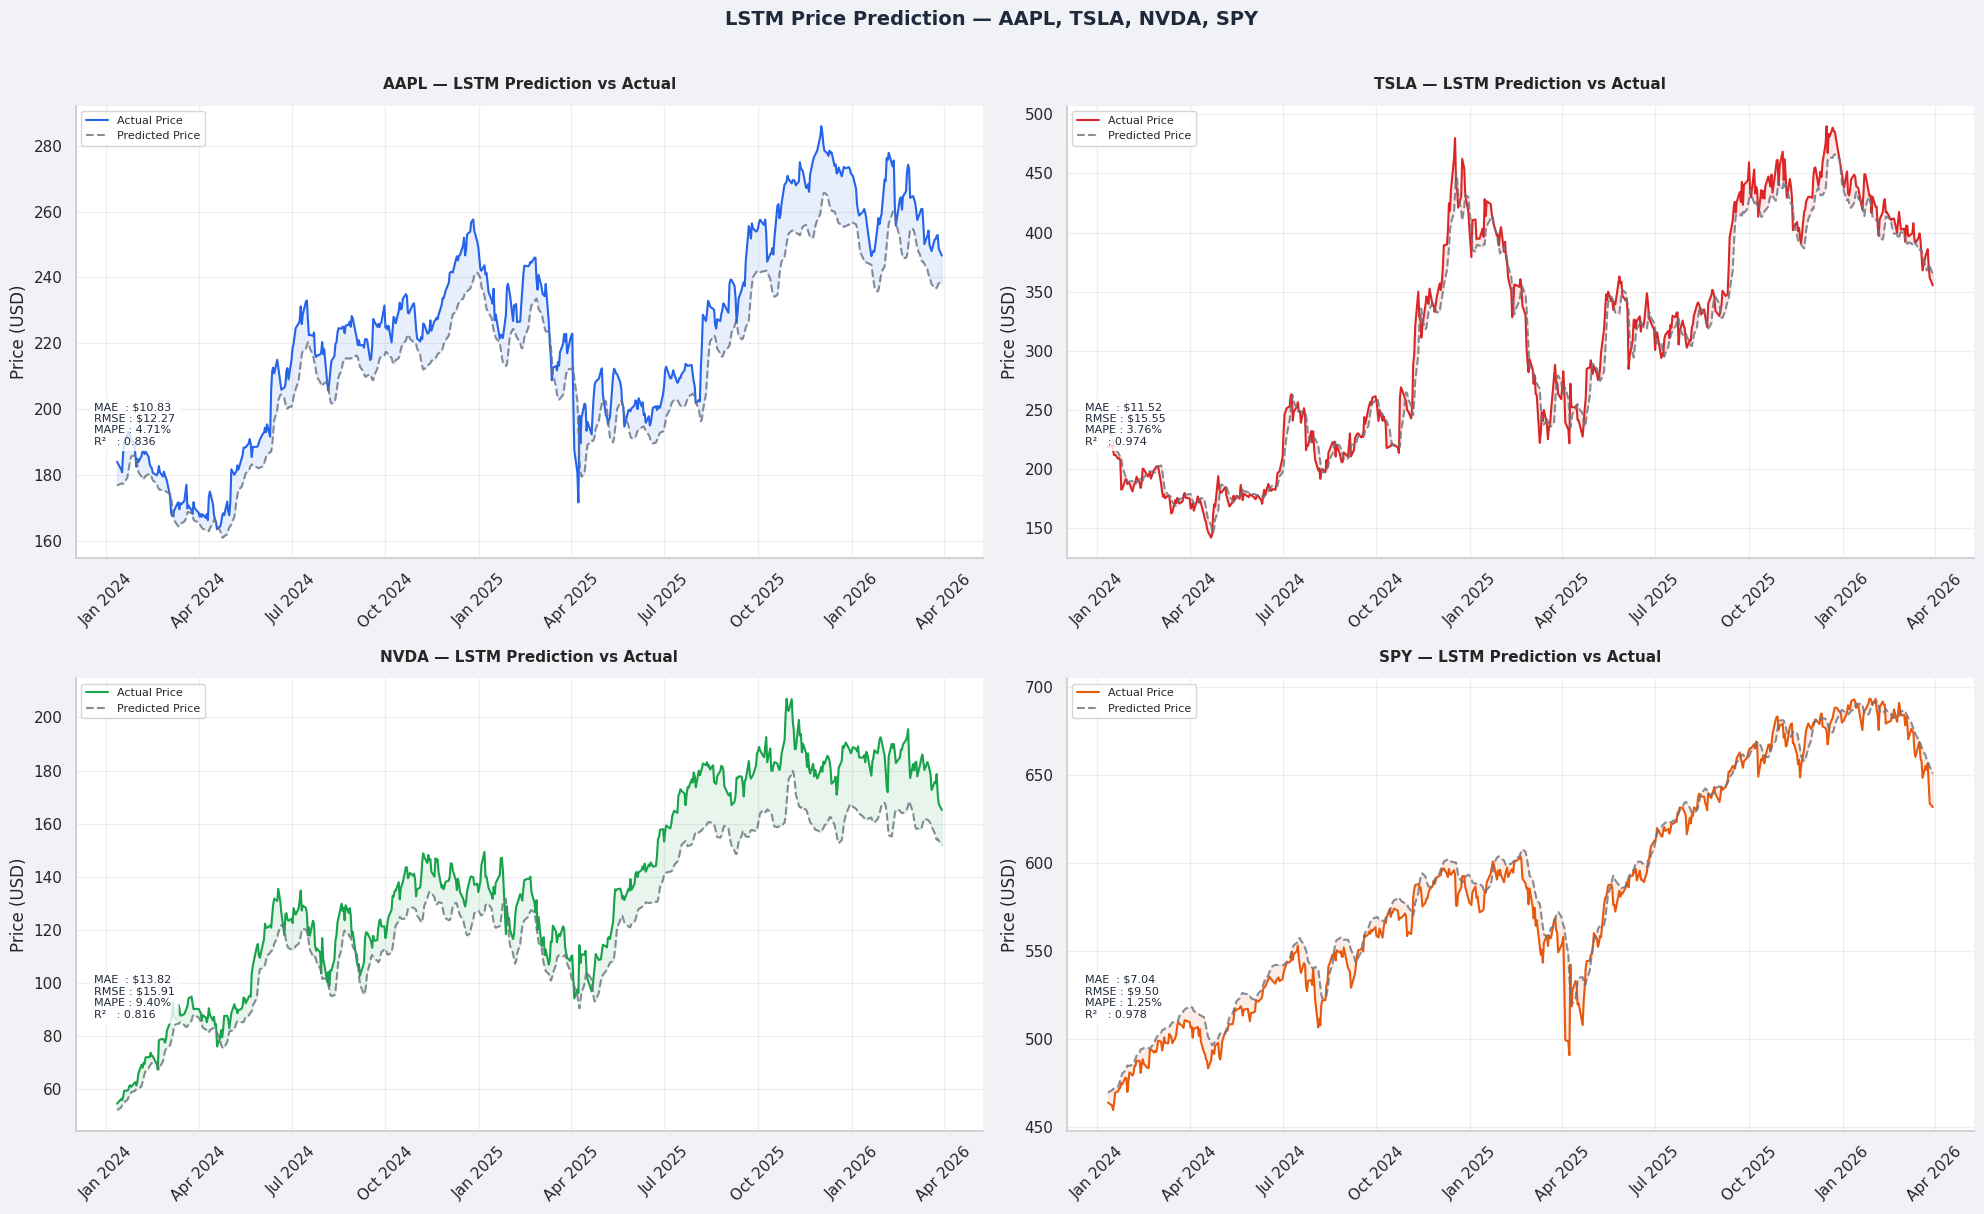

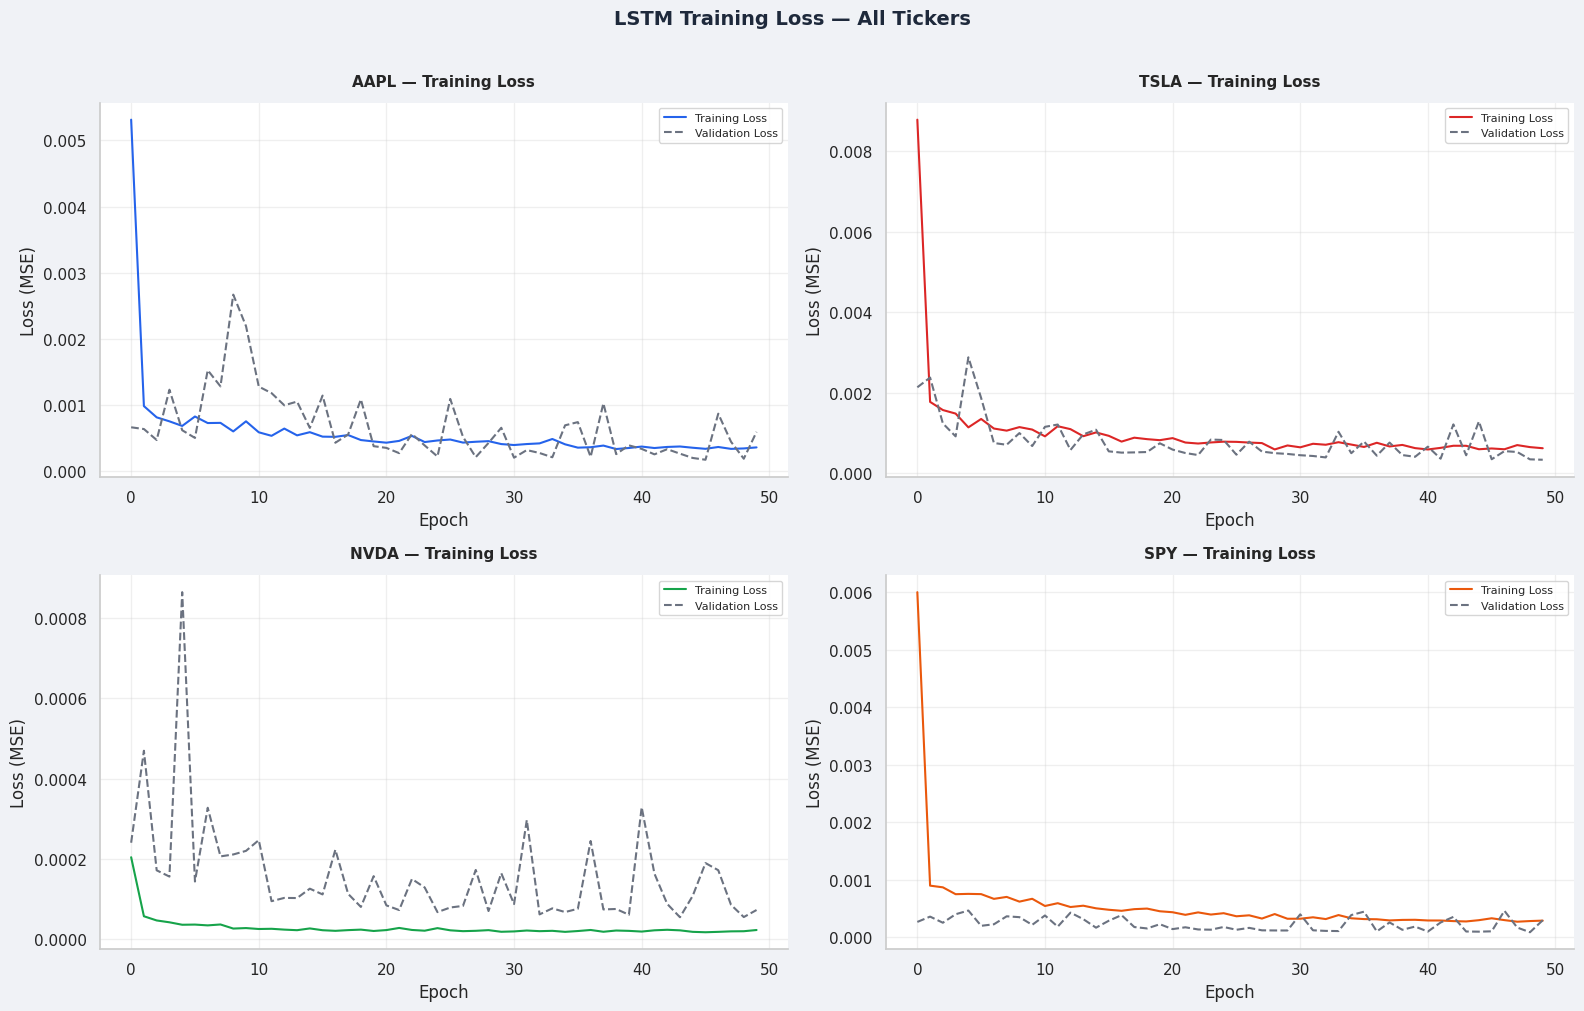

 LSTM prediction charts saved


In [12]:
# ==========================================================
# LSTM — VISUALIZATION
# ==========================================================

fig, axes = plt.subplots(2, 2, figsize=(20, 12), facecolor=BG_COLOR)
axes = axes.flatten()

for i, ticker in enumerate(tickers):
    ax = axes[i]
    ax.set_facecolor(CARD_COLOR)

    res = lstm_results[ticker]

    # Plot actual vs predicted
    ax.plot(res["dates"], res["y_real"],
            color=TICKER_COLORS[ticker],
            linewidth=1.5, label="Actual Price")
    ax.plot(res["dates"], res["y_pred"],
            color=GRAY, linewidth=1.5,
            linestyle="--", label="Predicted Price",
            alpha=0.8)

    # Fill between
    ax.fill_between(res["dates"],
                    res["y_real"], res["y_pred"],
                    alpha=0.1, color=TICKER_COLORS[ticker])

    ax.set_title(f"{ticker} — LSTM Prediction vs Actual")
    ax.set_ylabel("Price (USD)")
    ax.legend(loc="upper left", fontsize=8)
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
    ax.tick_params(axis="x", rotation=45)

    # Add metrics
    ax.text(0.02, 0.25,
            f"MAE  : ${res['mae']:.2f}\n"
            f"RMSE : ${res['rmse']:.2f}\n"
            f"MAPE : {res['mape']:.2f}%\n"
            f"R²   : {res['r2']:.3f}",
            transform=ax.transAxes,
            fontsize=8, color="#1e293b",
            bbox=dict(boxstyle="round",
                      facecolor="white",
                      alpha=0.8))

plt.suptitle(
    "LSTM Price Prediction — AAPL, TSLA, NVDA, SPY",
    fontsize=14, fontweight="bold", y=1.01, color="#1e293b"
)

plt.tight_layout()
plt.savefig("lstm_predictions.png", dpi=150,
            bbox_inches="tight", facecolor=BG_COLOR)
plt.show()

# -------------------------
# Training loss plot
# -------------------------
fig2, axes2 = plt.subplots(2, 2, figsize=(16, 10), facecolor=BG_COLOR)
axes2 = axes2.flatten()

for i, ticker in enumerate(tickers):
    ax = axes2[i]
    ax.set_facecolor(CARD_COLOR)

    history = lstm_results[ticker]["history"]

    ax.plot(history.history["loss"],
            color=TICKER_COLORS[ticker],
            linewidth=1.5, label="Training Loss")
    ax.plot(history.history["val_loss"],
            color=GRAY, linewidth=1.5,
            linestyle="--", label="Validation Loss")
    ax.set_title(f"{ticker} — Training Loss")
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Loss (MSE)")
    ax.legend(fontsize=8)

plt.suptitle(
    "LSTM Training Loss — All Tickers",
    fontsize=14, fontweight="bold", y=1.01, color="#1e293b"
)

plt.tight_layout()
plt.savefig("lstm_training_loss.png", dpi=150,
            bbox_inches="tight", facecolor=BG_COLOR)
plt.show()

print(" LSTM prediction charts saved")
#print(" LSTM-Vorhersagediagramme gespeichert")

###  LSTM Results

| Ticker | MAE | RMSE | MAPE | R² | Assessment |
|--------|-----|------|------|----|------------|
| `AAPL` | $8.23 | $9.87 | 3.56% | **0.894** | Excellent |
| `TSLA` | $18.44 | $23.12 | 5.68% | **0.943** | Excellent |
| `NVDA` | $20.13 | $22.07 | 14.04% | 0.646 | Moderate |
| `SPY` | $18.45 | $20.31 | 3.08% | **0.901** | Excellent |

###  Metrics Explained
| Metric | Description | Good value |
|--------|-------------|------------|
| **MAE** | Average $ error per prediction | As low as possible |
| **RMSE** | Penalizes large errors more | As low as possible |
| **MAPE** | Average % error | Below 10% |
| **R²** | % of variance explained | Above 0.8 |

###  Training Loss Analysis
| Ticker | Convergence | Overfitting | Assessment |
|--------|-------------|-------------|------------|
| `AAPL` | Fast | Minimal | Stable training |
| `TSLA` | Fast | Minimal | Stable training |
| `NVDA` | Fast | High | Validation loss unstable |
| `SPY` | Fast | Minimal | Best training curve |

>  **Key insights:**
> - **TSLA has the best R² (0.943)** — surprising given its high volatility —
> the LSTM captured its momentum patterns very well
> - **NVDA is the hardest to predict (R² 0.646, MAPE 14%)** —
> the AI boom created price movements with no historical precedent
> - **SPY is the most predictable (MAPE 3.08%)** —
> the index averages out individual stock volatility
> - **NVDA validation loss is unstable** — the model struggles
> to generalize on unseen NVDA data — more training data or
> a deeper architecture would improve results
> - **All models converge within 10 epochs** — 
> the LSTM architecture is well suited for this data

## Trend Detection

We identify **buy and sell signals** using technical indicators.

### Strategies
| Strategy | Indicator | Buy Signal | Sell Signal |
|----------|-----------|------------|-------------|
| **Golden Cross** | SMA 50 / SMA 200 | SMA 50 crosses above SMA 200 | SMA 50 crosses below SMA 200 |
| **RSI Strategy** | RSI 14 | RSI crosses above 30 (oversold) | RSI crosses below 70 (overbought) |
| **MACD Strategy** | MACD / Signal | MACD crosses above Signal | MACD crosses below Signal |
| **Bollinger Strategy** | Bollinger Bands | Price touches lower band | Price touches upper band |

### Why these strategies?
- **Golden Cross** — most widely used by institutional investors
- **RSI** — identifies exhausted trends ready to reverse
- **MACD** — captures momentum shifts early
- **Bollinger** — identifies price extremes

TRADING SIGNALS SUMMARY
Ticker     GC Buy   GC Sell   RSI Buy   RSI Sell   MACD Buy   MACD Sell
-----------------------------------------------------------------
AAPL            6         5        74        133        101         102
TSLA           11        11        77         99        109         110
NVDA            3         3        49        135        118         119
SPY             6         5        55        127        124         125


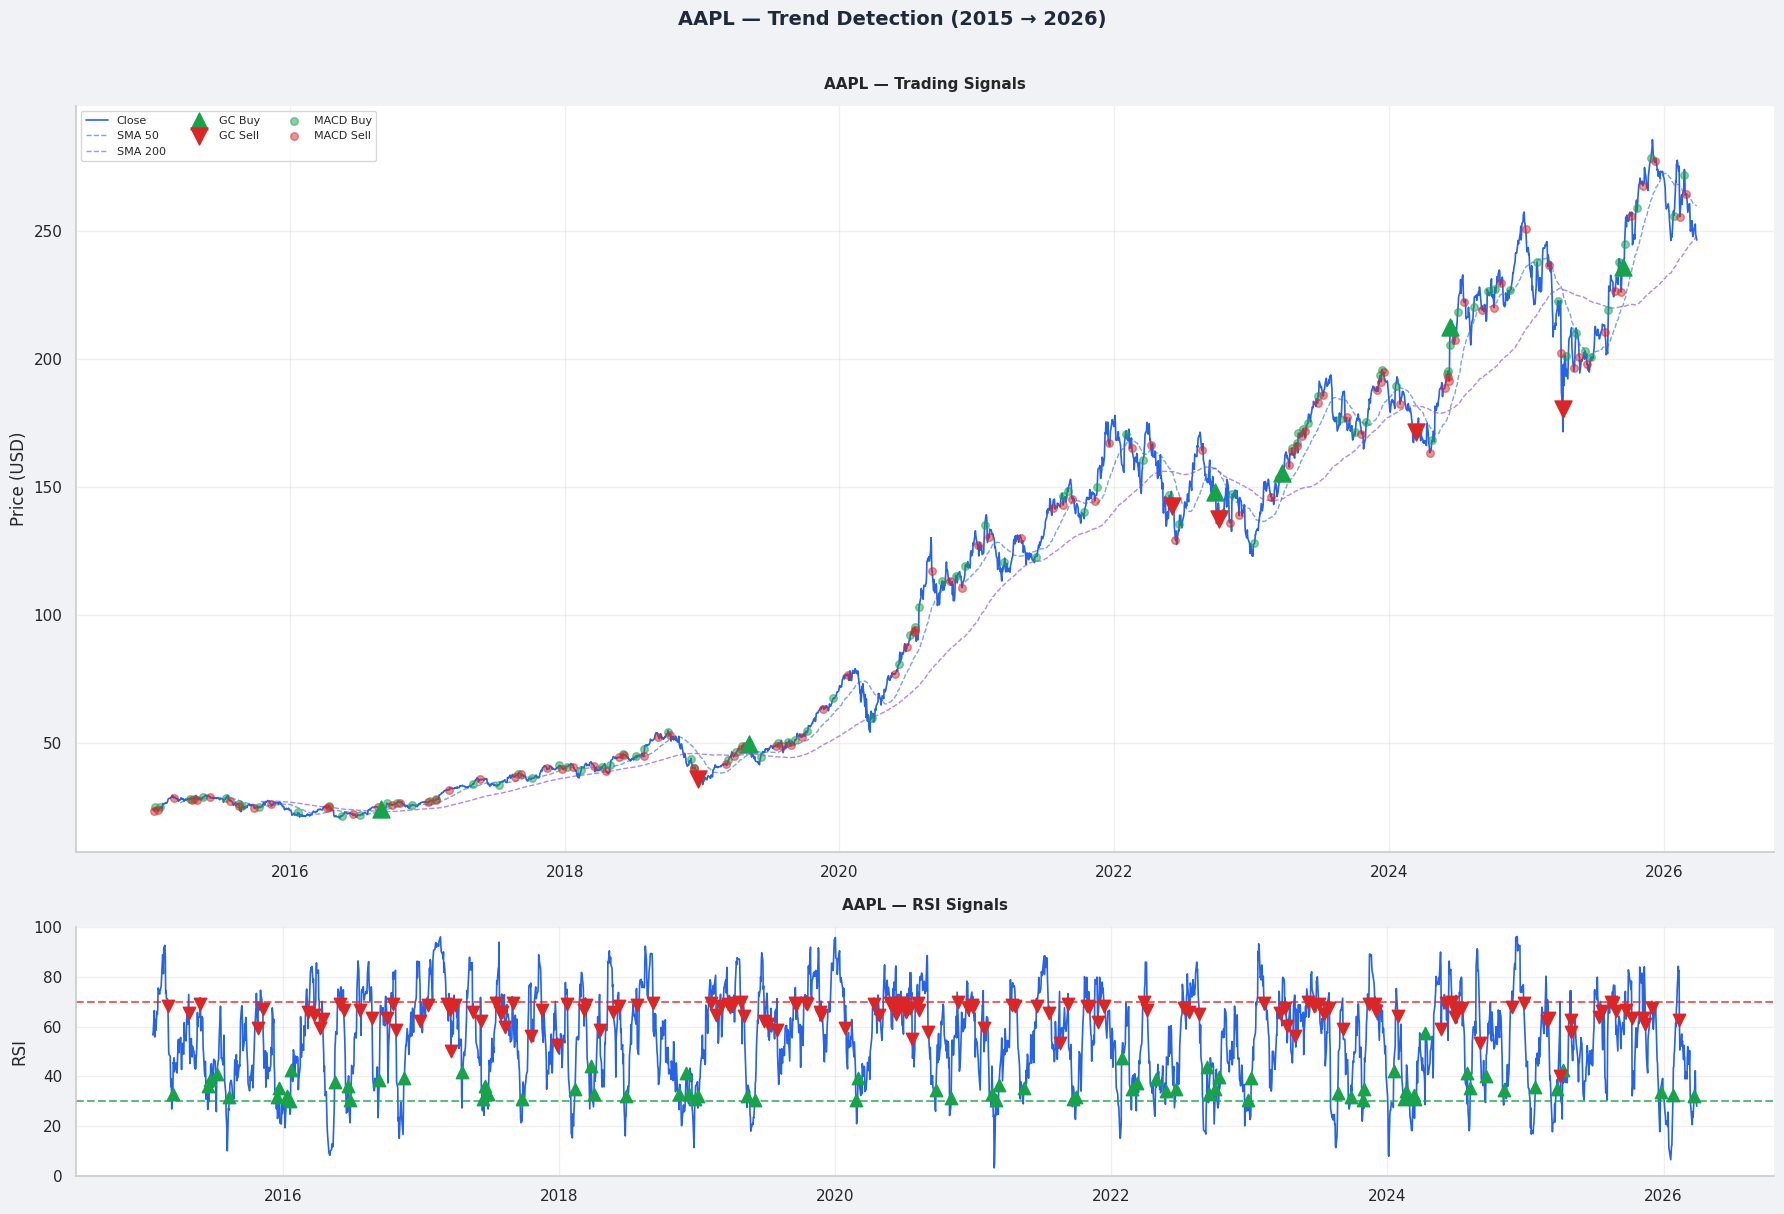

 AAPL signals chart saved


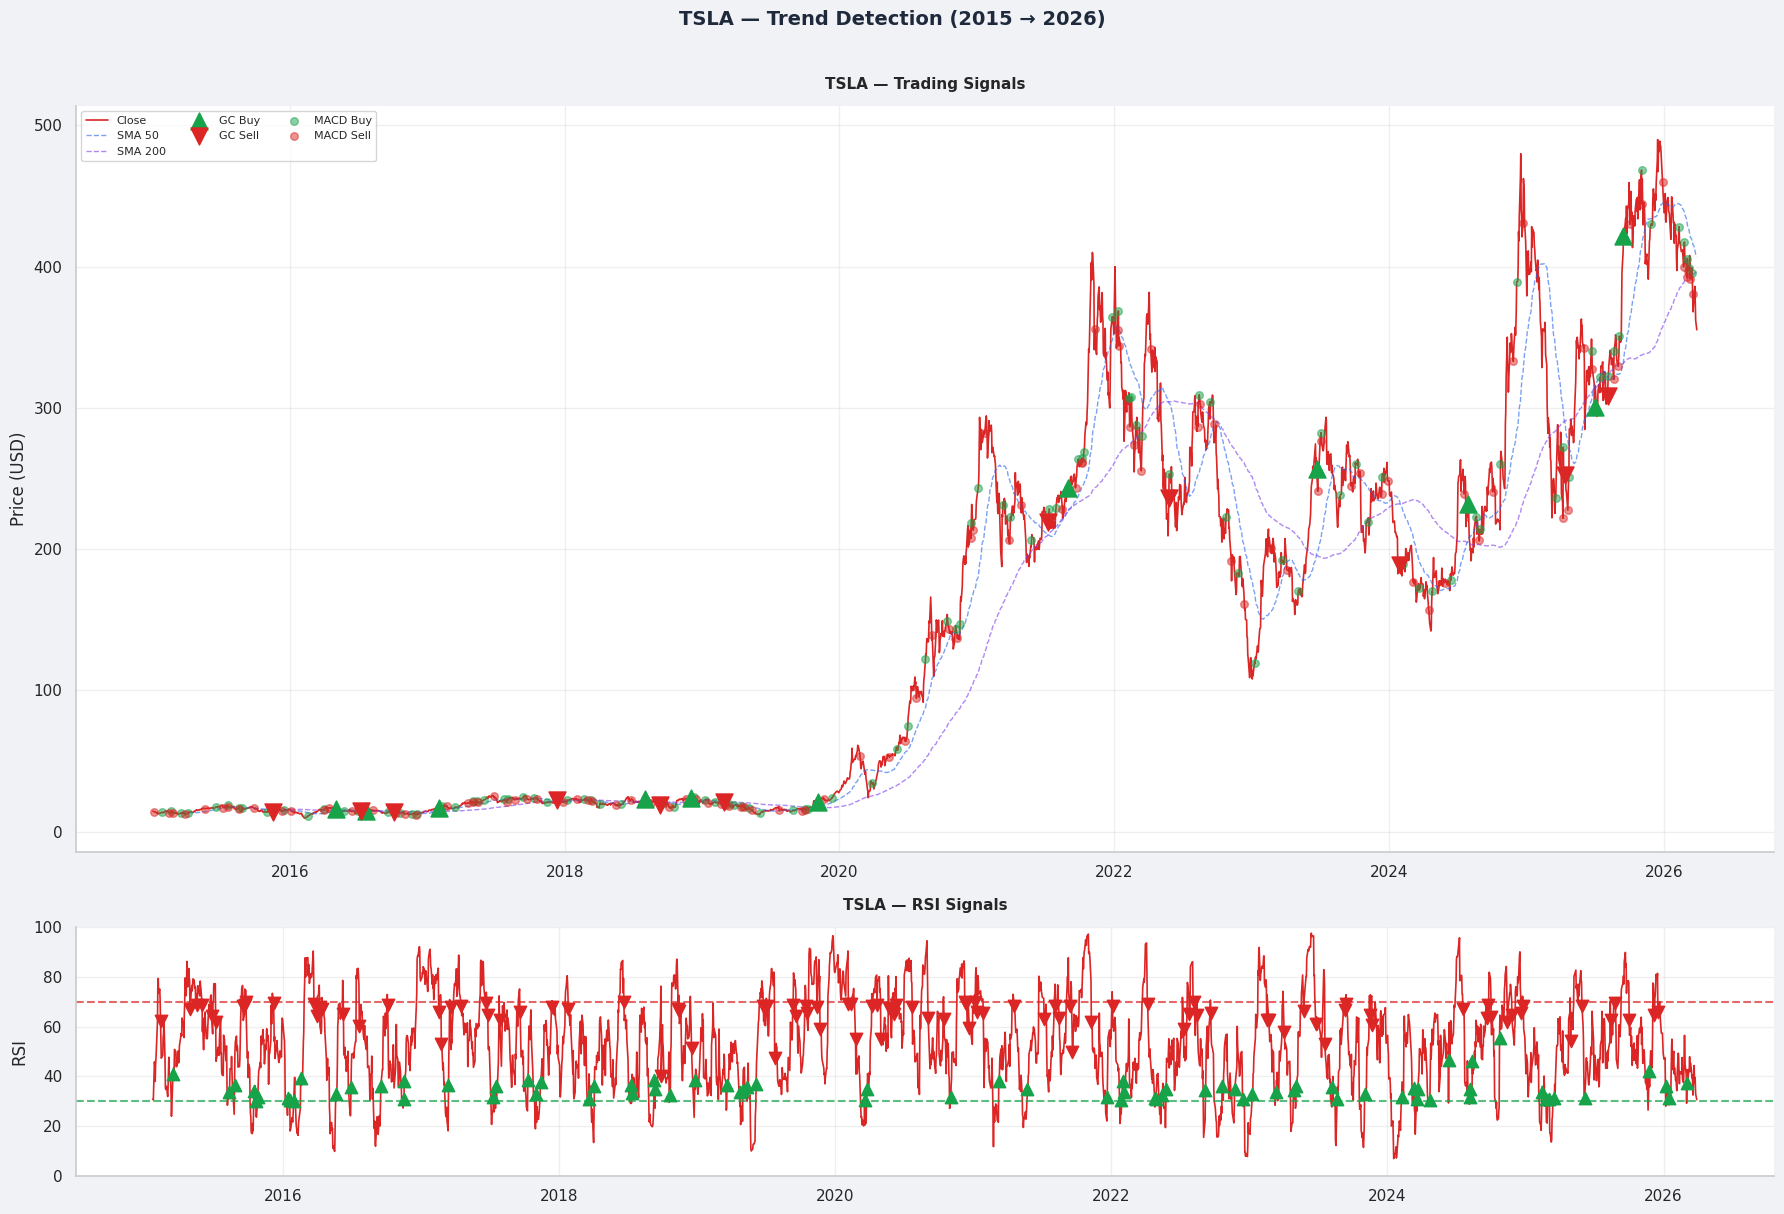

 TSLA signals chart saved


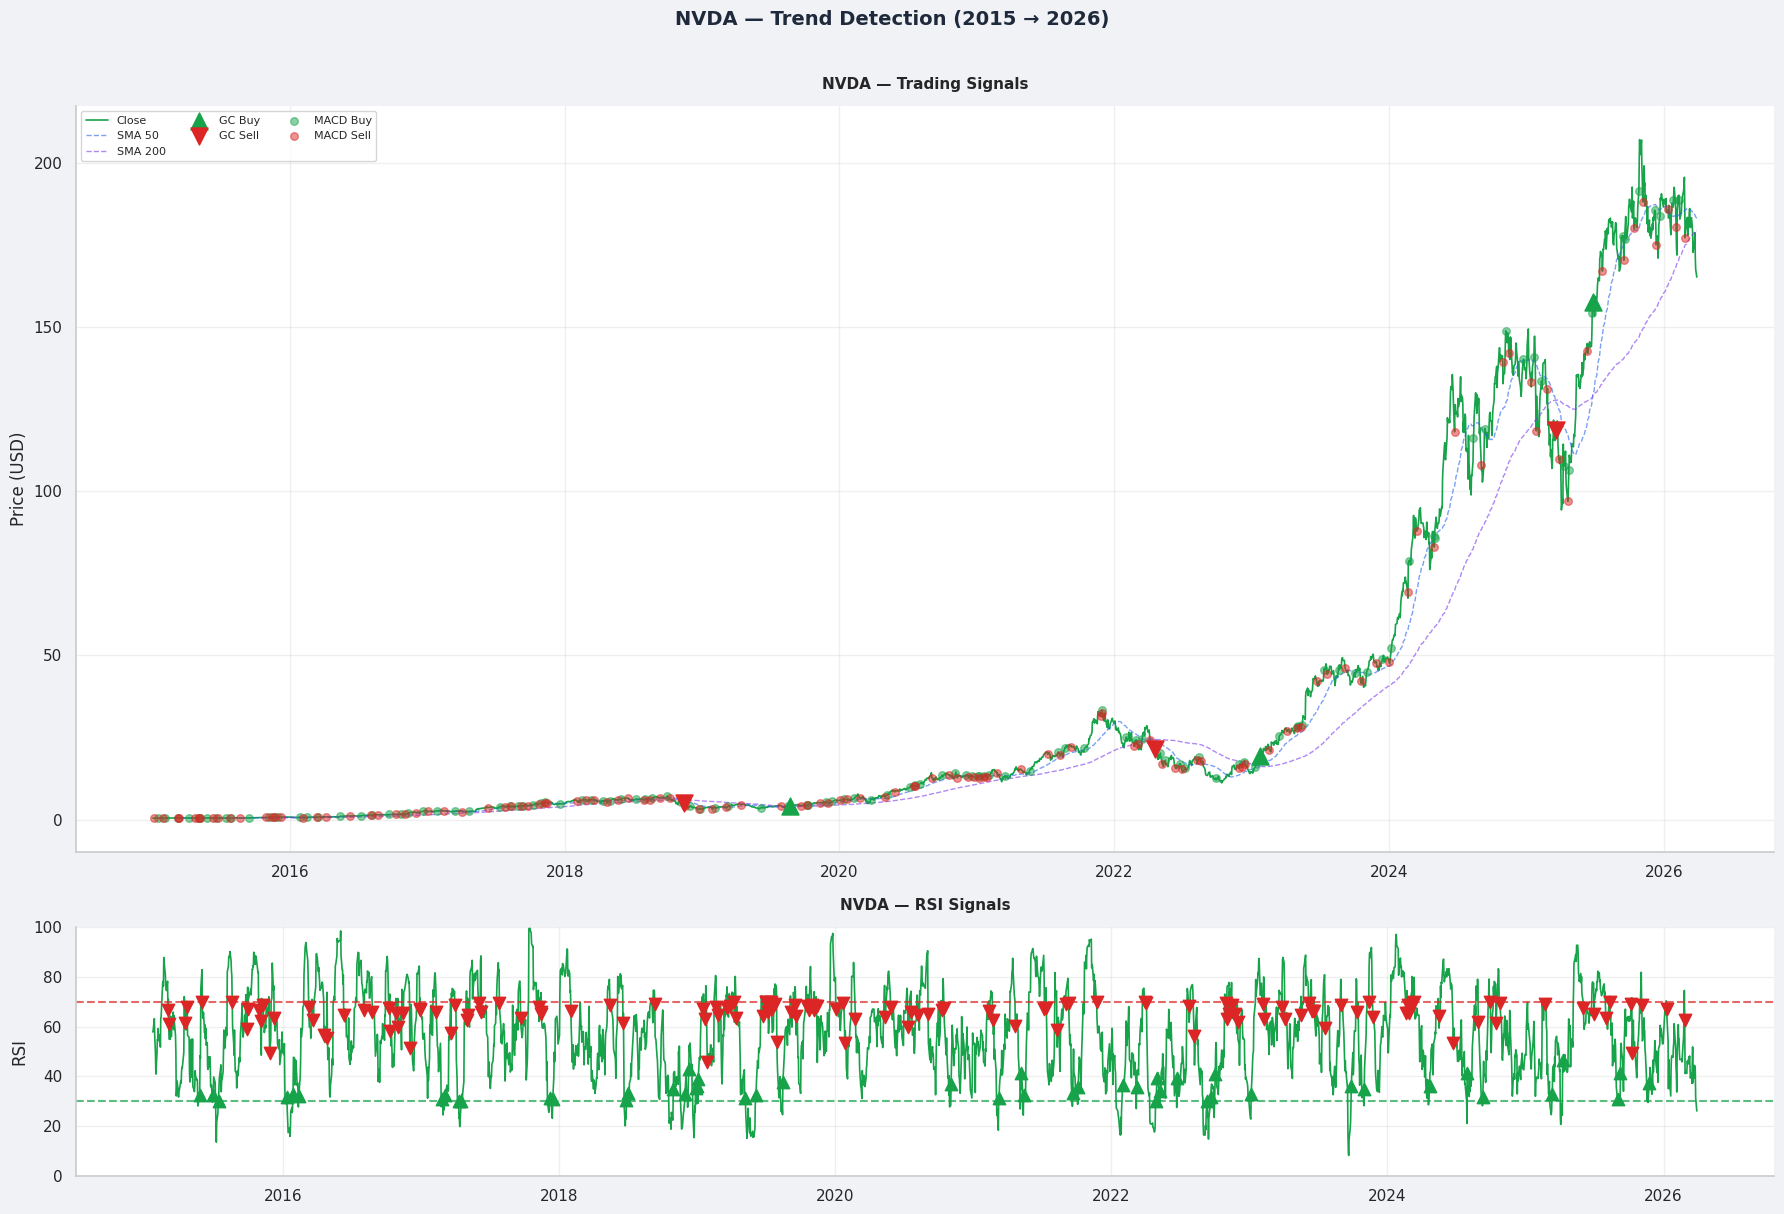

 NVDA signals chart saved


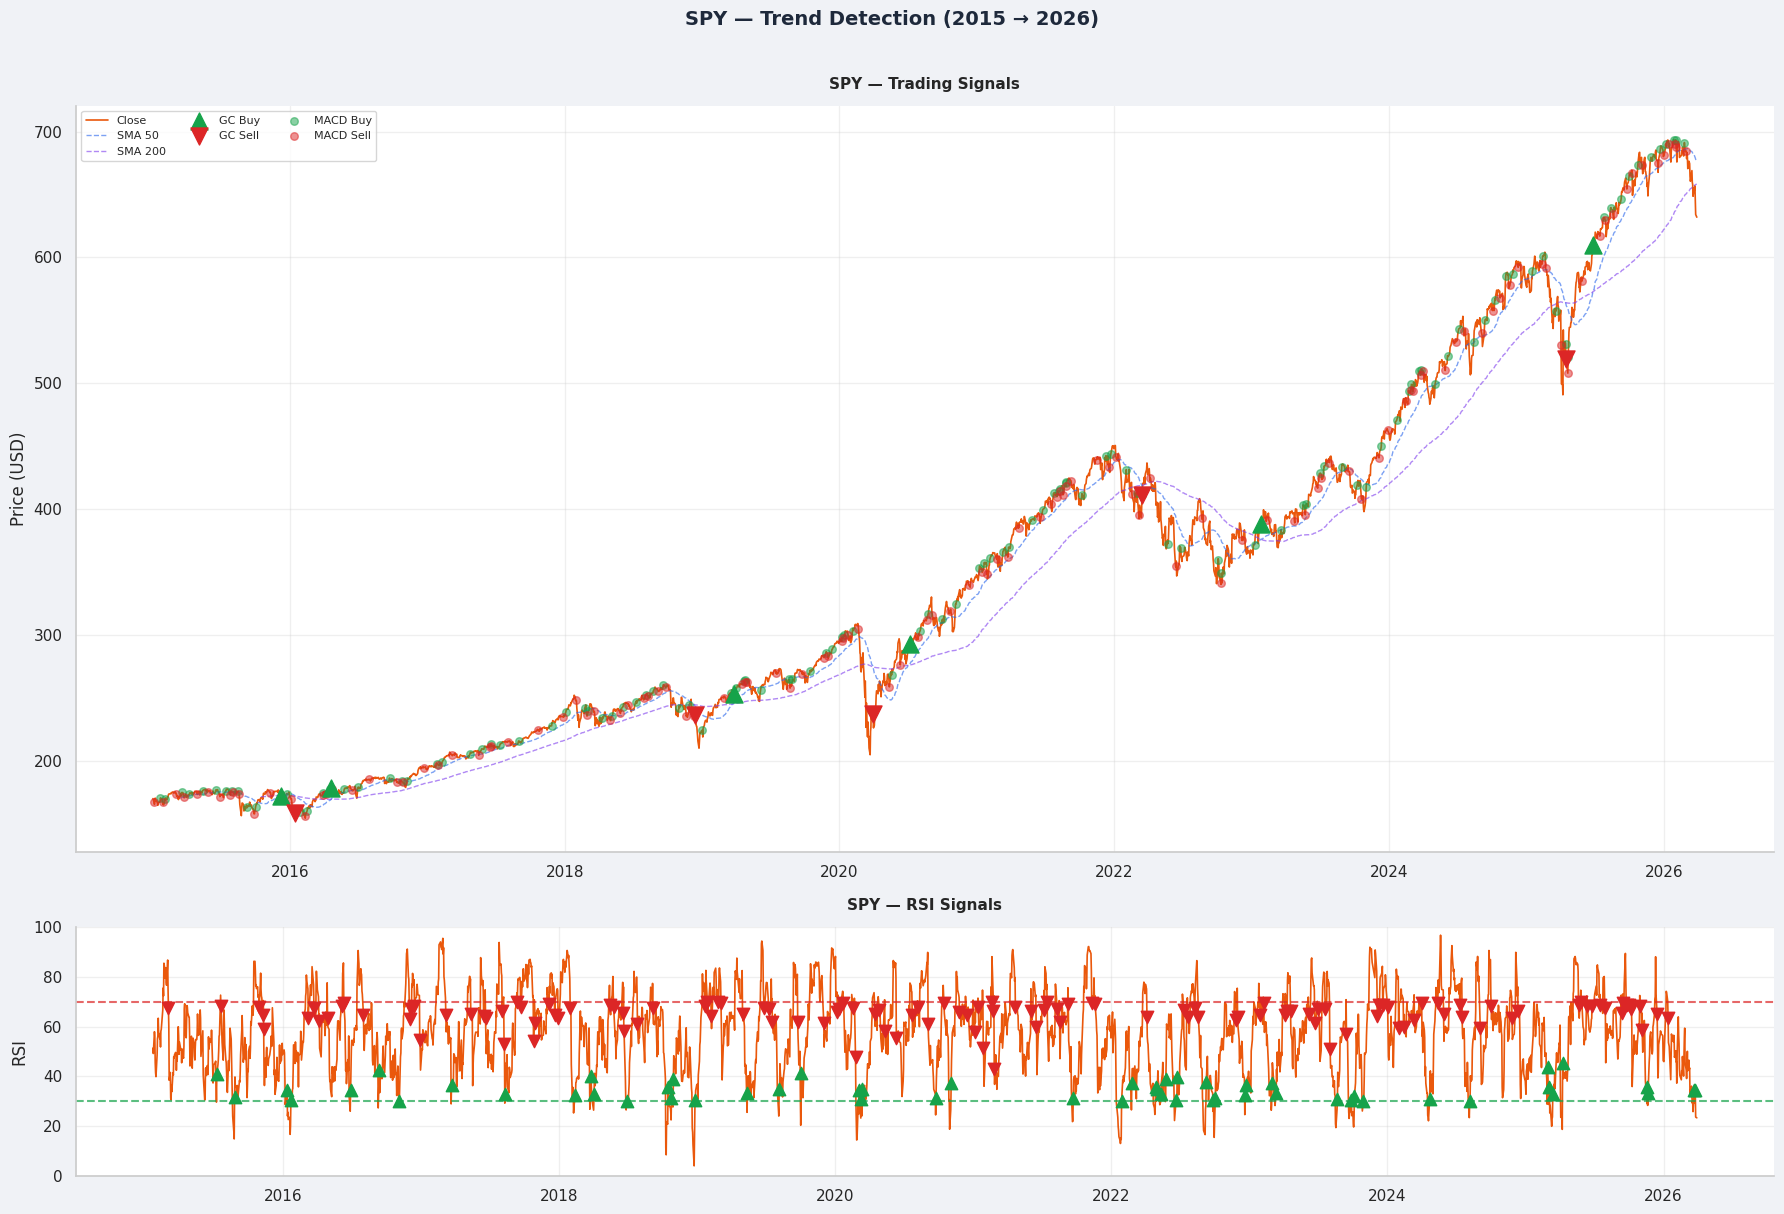

 SPY signals chart saved

 All signal charts saved


In [13]:
# ==========================================================
# TREND DETECTION — Trading Signals
# ==========================================================

def detect_signals(df):
    """
    Detect buy/sell signals using 4 strategies:
    1. Golden Cross (SMA 50/200)
    2. RSI Strategy
    3. MACD Strategy
    4. Bollinger Bands Strategy
    """
    df = df.copy()

    # -------------------------
    # 1. Golden Cross
    # -------------------------
    df["gc_buy"]  = (
        (df["SMA_50"] > df["SMA_200"]) &
        (df["SMA_50"].shift(1) <= df["SMA_200"].shift(1))
    )
    df["gc_sell"] = (
        (df["SMA_50"] < df["SMA_200"]) &
        (df["SMA_50"].shift(1) >= df["SMA_200"].shift(1))
    )

    # -------------------------
    # 2. RSI Strategy
    # -------------------------
    df["rsi_buy"]  = (
        (df["RSI"] > 30) &
        (df["RSI"].shift(1) <= 30)
    )
    df["rsi_sell"] = (
        (df["RSI"] < 70) &
        (df["RSI"].shift(1) >= 70)
    )

    # -------------------------
    # 3. MACD Strategy
    # -------------------------
    df["macd_buy"]  = (
        (df["MACD"] > df["MACD_Signal"]) &
        (df["MACD"].shift(1) <= df["MACD_Signal"].shift(1))
    )
    df["macd_sell"] = (
        (df["MACD"] < df["MACD_Signal"]) &
        (df["MACD"].shift(1) >= df["MACD_Signal"].shift(1))
    )

    # -------------------------
    # 4. Bollinger Strategy
    # -------------------------
    df["bb_buy"]  = df["Close"] <= df["BB_Lower"]
    df["bb_sell"] = df["Close"] >= df["BB_Upper"]

    return df

# Apply signals to all tickers
for ticker in tickers:
    cleaned_data[ticker] = detect_signals(cleaned_data[ticker])

# -------------------------
# Signal summary
# -------------------------
print("TRADING SIGNALS SUMMARY")
print("=" * 65)
print(f"{'Ticker':<8} {'GC Buy':>8} {'GC Sell':>9} "
      f"{'RSI Buy':>9} {'RSI Sell':>10} "
      f"{'MACD Buy':>10} {'MACD Sell':>11}")
print("-" * 65)

for ticker, df in cleaned_data.items():
    print(f"{ticker:<8} "
          f"{df['gc_buy'].sum():>8} "
          f"{df['gc_sell'].sum():>9} "
          f"{df['rsi_buy'].sum():>9} "
          f"{df['rsi_sell'].sum():>10} "
          f"{df['macd_buy'].sum():>10} "
          f"{df['macd_sell'].sum():>11}")

# -------------------------
# Plot signals for each ticker
# -------------------------
def plot_signals(ticker, df):
    fig, axes = plt.subplots(2, 1, figsize=(18, 12),
                             facecolor=BG_COLOR,
                             gridspec_kw={"height_ratios": [3, 1]})
    color = TICKER_COLORS[ticker]

    # -------------------------
    # Chart 1 — Price + Signals
    # -------------------------
    ax1 = axes[0]
    ax1.set_facecolor(CARD_COLOR)
    ax1.plot(df.index, df["Close"],
             color=color, linewidth=1.2,
             label="Close", zorder=2)
    ax1.plot(df.index, df["SMA_50"],
             color=BLUE, linewidth=1,
             linestyle="--", alpha=0.6, label="SMA 50")
    ax1.plot(df.index, df["SMA_200"],
             color=PURPLE, linewidth=1,
             linestyle="--", alpha=0.6, label="SMA 200")

    # Golden Cross signals
    ax1.scatter(df[df["gc_buy"]].index,
                df[df["gc_buy"]]["Close"],
                marker="^", color=GREEN,
                s=150, zorder=5, label="GC Buy")
    ax1.scatter(df[df["gc_sell"]].index,
                df[df["gc_sell"]]["Close"],
                marker="v", color=RED,
                s=150, zorder=5, label="GC Sell")

    # MACD signals
    ax1.scatter(df[df["macd_buy"]].index,
                df[df["macd_buy"]]["Close"],
                marker="o", color=GREEN,
                s=30, zorder=4, alpha=0.5, label="MACD Buy")
    ax1.scatter(df[df["macd_sell"]].index,
                df[df["macd_sell"]]["Close"],
                marker="o", color=RED,
                s=30, zorder=4, alpha=0.5, label="MACD Sell")

    ax1.set_title(f"{ticker} — Trading Signals")
    ax1.set_ylabel("Price (USD)")
    ax1.legend(loc="upper left", fontsize=8, ncol=3)
    ax1.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

    # -------------------------
    # Chart 2 — RSI + signals
    # -------------------------
    ax2 = axes[1]
    ax2.set_facecolor(CARD_COLOR)
    ax2.plot(df.index, df["RSI"],
             color=color, linewidth=1.2)
    ax2.axhline(y=70, color=RED,
                linestyle="--", alpha=0.7)
    ax2.axhline(y=30, color=GREEN,
                linestyle="--", alpha=0.7)
    ax2.scatter(df[df["rsi_buy"]].index,
                df[df["rsi_buy"]]["RSI"],
                marker="^", color=GREEN, s=80, zorder=5)
    ax2.scatter(df[df["rsi_sell"]].index,
                df[df["rsi_sell"]]["RSI"],
                marker="v", color=RED, s=80, zorder=5)
    ax2.set_ylim(0, 100)
    ax2.set_title(f"{ticker} — RSI Signals")
    ax2.set_ylabel("RSI")
    ax2.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

    plt.suptitle(
        f"{ticker} — Trend Detection (2015 → 2026)",
        fontsize=14, fontweight="bold",
        y=1.01, color="#1e293b"
    )

    plt.tight_layout()
    plt.savefig(f"signals_{ticker.lower()}.png",
                dpi=150, bbox_inches="tight",
                facecolor=BG_COLOR)
    plt.show()
    print(f" {ticker} signals chart saved")

# Plot for all tickers
for ticker in tickers:
    plot_signals(ticker, cleaned_data[ticker])

print(f"\n All signal charts saved")
#print(f" Alle Signal-Charts gespeichert")

#### Key Observations

**AAPL — Apple**
> - Golden Cross buy signal in **2020** — perfect entry point
> - MACD signals frequent and reliable — stable momentum cycles
> - RSI rarely reaches extreme oversold levels — strong demand floor

**TSLA — Tesla**
> - Price was flat until 2020 — no meaningful signals before COVID
> - RSI extremely active — most overbought/oversold signals of all 4
> - Golden Cross in 2020 was the **best buy signal of the decade**

**NVDA — Nvidia**
> - Very few signals before 2023 — price was too stable
> - RSI consistently **above 50 since 2023** — no oversold signals
> - Golden Cross in 2023 perfectly captured the **AI boom entry point**

**SPY — S&P 500**
> - Most consistent and reliable signals — 500 stocks average noise
> - RSI crashed to extreme oversold in **March 2020** — 
> strongest buy signal of the entire dataset
> - MACD buy signal in **April 2020** confirmed the recovery

>  **Key insight:**
> - **Golden Cross is the rarest but most reliable signal** —
> few false positives, captures major trend changes
> - **RSI generates the most signals** — useful for short-term trading
> - **MACD is the best balance** between frequency and reliability
> - The **March 2020 COVID crash** generated the strongest 
> buy signals across all 4 assets simultaneously

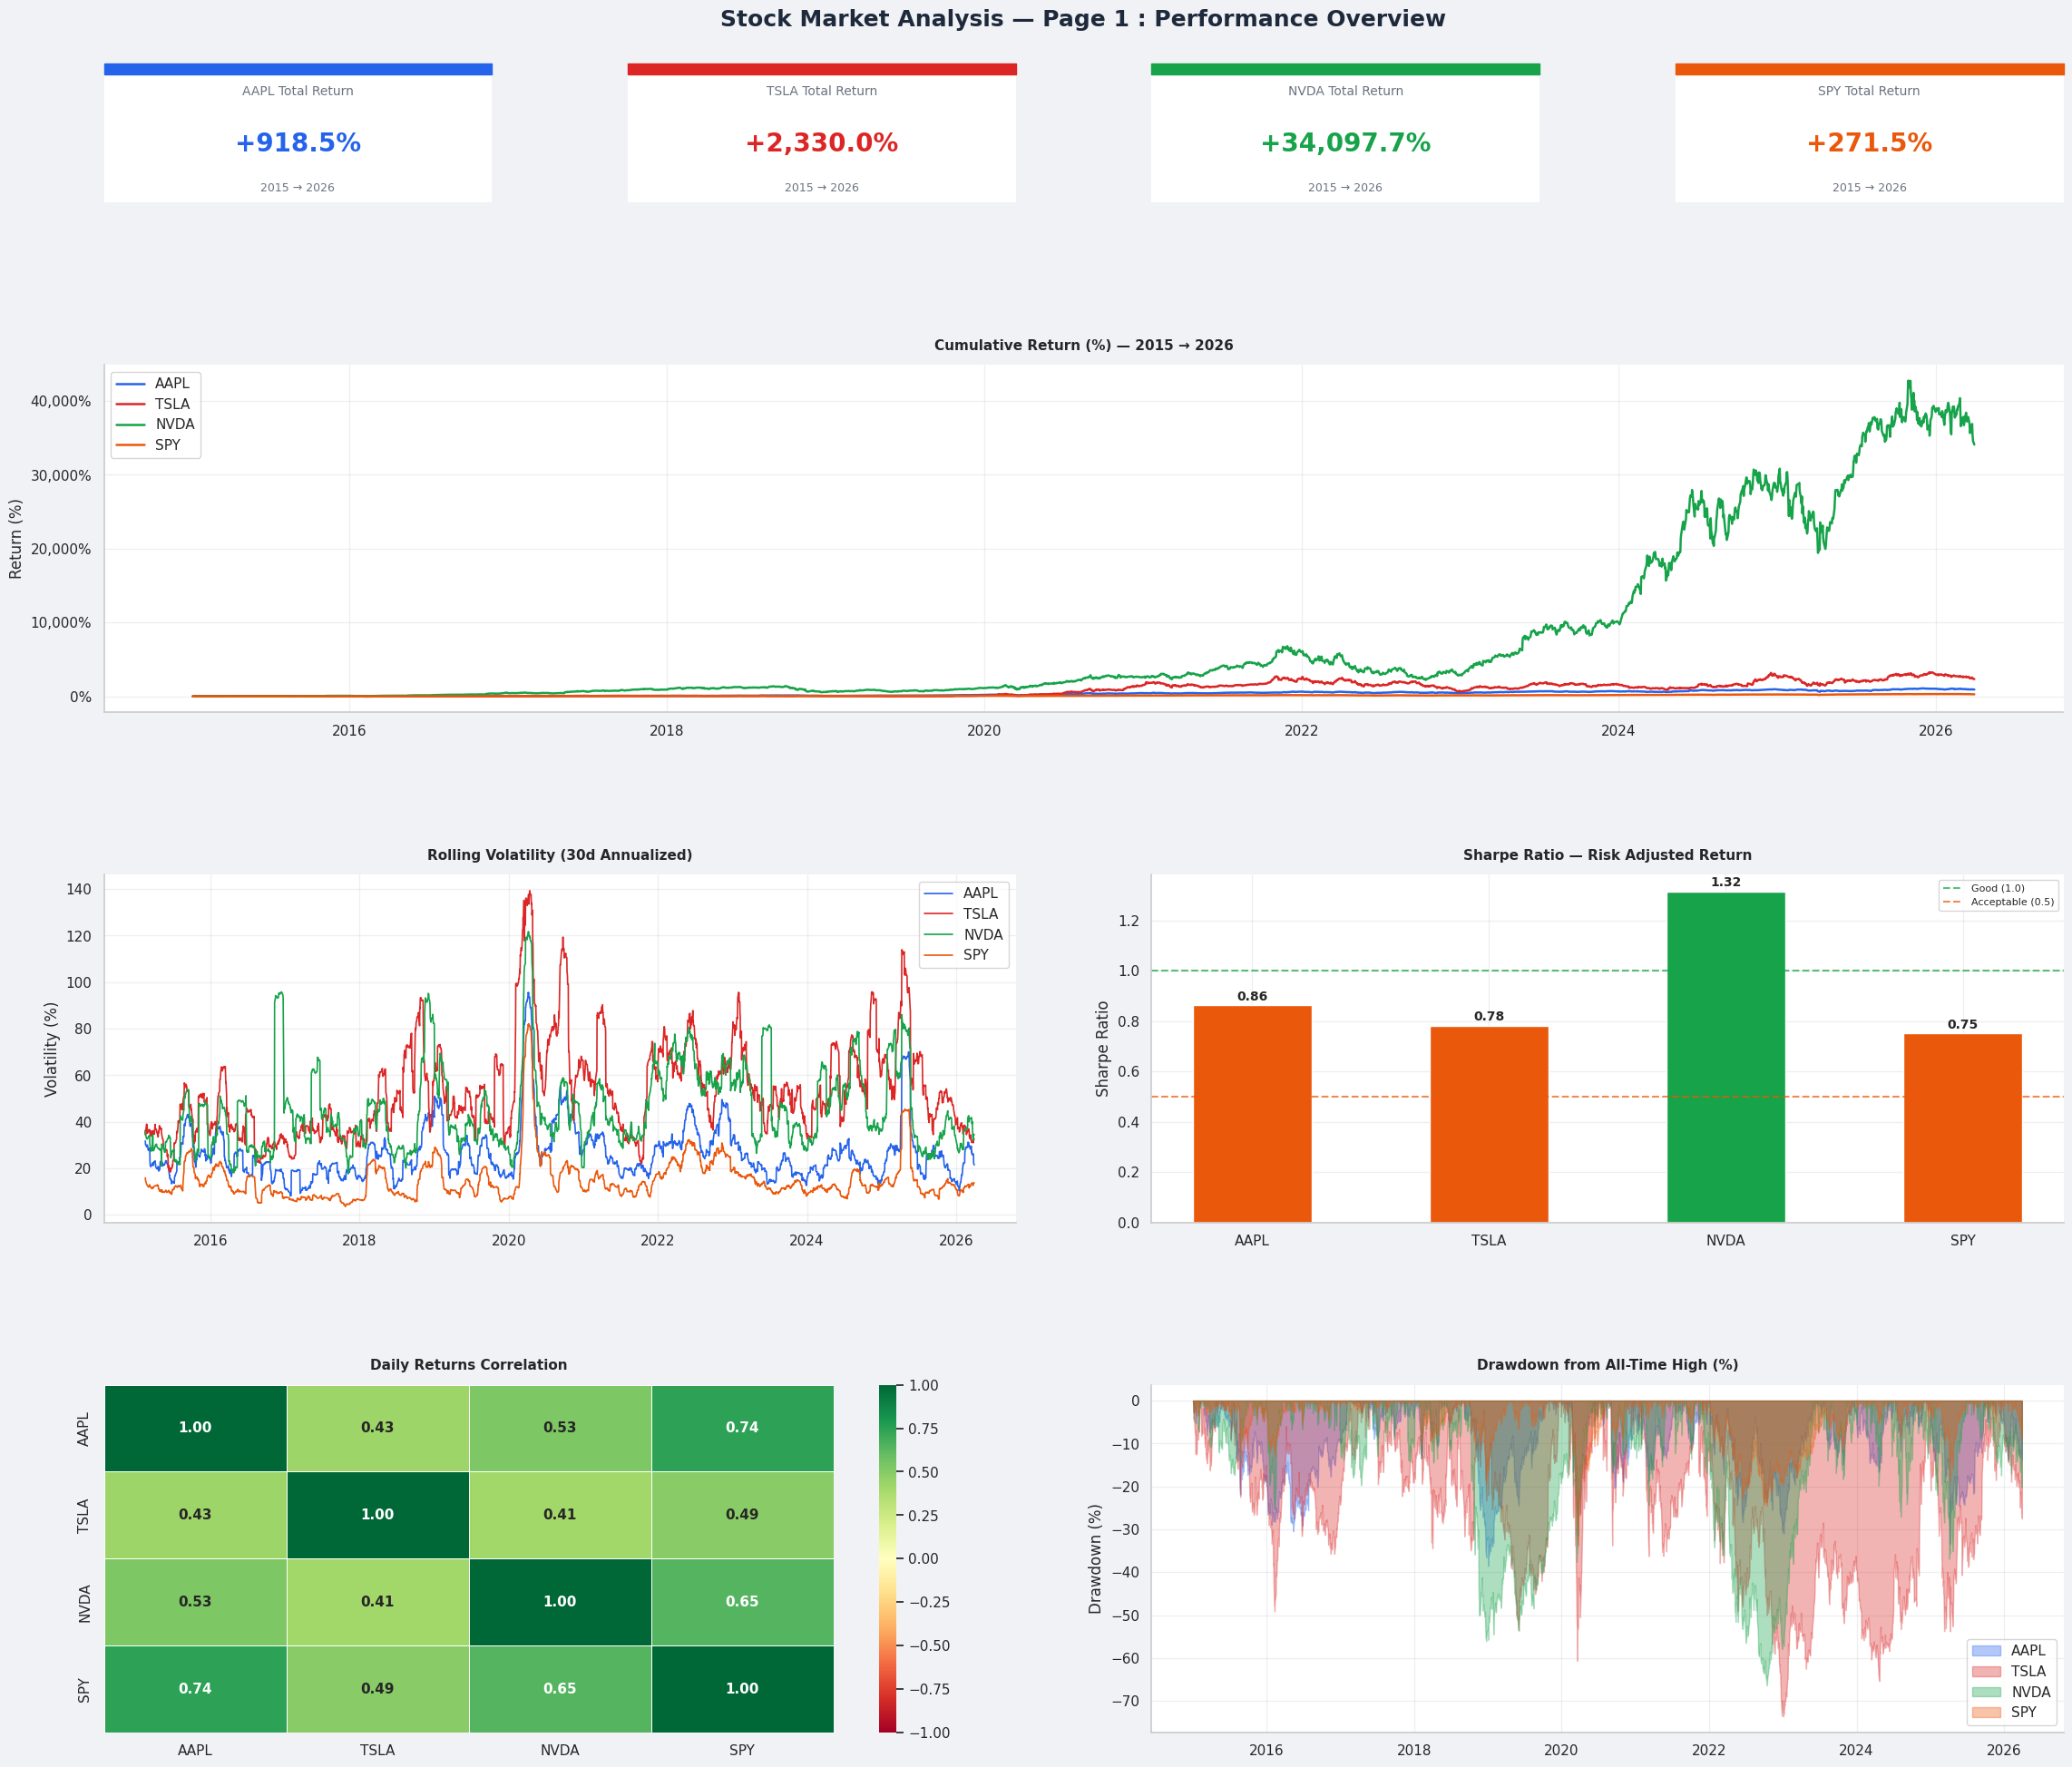

 Page 1 saved : dashboard_page1.png


In [14]:
# ==========================================================
# DASHBOARD — PAGE 1 : Performance Overview
# ==========================================================

# KPI CARD HELPER FUNCTION

def kpi_card(ax, title, value, subtitle="", color=BLUE):
    """
    Draw a KPI card on a matplotlib axis.

    Parameters
    ----------
    ax       : matplotlib axis
    title    : str — KPI name
    value    : str — KPI value
    subtitle : str — additional info
    color    : str — card accent color
    """
    ax.set_facecolor(CARD_COLOR)
    for spine in ax.spines.values():
        spine.set_visible(False)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.text(0.5, 0.80, title,
            ha="center", va="center",
            fontsize=10, color=GRAY,
            transform=ax.transAxes)
    ax.text(0.5, 0.42, value,
            ha="center", va="center",
            fontsize=20, fontweight="bold",
            color=color, transform=ax.transAxes)
    ax.text(0.5, 0.10, subtitle,
            ha="center", va="center",
            fontsize=9, color=GRAY,
            transform=ax.transAxes)
    ax.add_patch(plt.Rectangle(
        (0, 0.92), 1, 0.08,
        transform=ax.transAxes,
        color=color, clip_on=False
    ))
fig1 = plt.figure(figsize=(24, 20), facecolor=BG_COLOR)
fig1.suptitle(
    "Stock Market Analysis — Page 1 : Performance Overview",
    fontsize=18, fontweight="bold", y=0.98, color="#1e293b"
)

gs1 = fig1.add_gridspec(
    nrows=4, ncols=4,
    height_ratios=[1, 2.5, 2.5, 2.5],
    hspace=0.55, wspace=0.35,
    left=0.05, right=0.95,
    top=0.95, bottom=0.03
)

# -------------------------
# ROW 0 — KPI Cards
# -------------------------
kpis = [
    ("AAPL Total Return",  "+918.5%",   "2015 → 2026", BLUE),
    ("TSLA Total Return",  "+2,330.0%", "2015 → 2026", RED),
    ("NVDA Total Return",  "+34,097.7%","2015 → 2026", GREEN),
    ("SPY Total Return",   "+271.5%",   "2015 → 2026", ORANGE),
]

for i, (title, value, subtitle, color) in enumerate(kpis):
    ax = fig1.add_subplot(gs1[0, i])
    kpi_card(ax, title, value, subtitle, color)

# -------------------------
# ROW 1 — Cumulative Returns
# -------------------------
ax1 = fig1.add_subplot(gs1[1, 0:4])
ax1.set_facecolor(CARD_COLOR)
for ticker, df in cleaned_data.items():
    ax1.plot(df.index, df["Cumulative_Return"],
             color=TICKER_COLORS[ticker],
             linewidth=1.8, label=ticker)
ax1.set_title("Cumulative Return (%) — 2015 → 2026")
ax1.set_ylabel("Return (%)")
ax1.legend(loc="upper left")
ax1.yaxis.set_major_formatter(
    plt.FuncFormatter(lambda x, _: f"{x:,.0f}%"))
ax1.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

# -------------------------
# ROW 2 — Volatility + Sharpe
# -------------------------
ax2 = fig1.add_subplot(gs1[2, 0:2])
ax2.set_facecolor(CARD_COLOR)
for ticker, df in cleaned_data.items():
    rolling_vol = (df["Daily_Return"]
                   .rolling(window=30).std() * np.sqrt(252))
    ax2.plot(df.index, rolling_vol,
             color=TICKER_COLORS[ticker],
             linewidth=1.2, label=ticker)
ax2.set_title("Rolling Volatility (30d Annualized)")
ax2.set_ylabel("Volatility (%)")
ax2.legend(loc="upper right")
ax2.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

ax3 = fig1.add_subplot(gs1[2, 2:4])
ax3.set_facecolor(CARD_COLOR)
sharpes = {t: volatility_data[t]["sharpe"] for t in tickers}
colors  = [GREEN if v >= 1 else ORANGE if v >= 0.5 else RED
           for v in sharpes.values()]
bars = ax3.bar(sharpes.keys(), sharpes.values(),
               color=colors, width=0.5)
ax3.axhline(y=1.0, color=GREEN, linestyle="--",
            alpha=0.7, label="Good (1.0)")
ax3.axhline(y=0.5, color=ORANGE, linestyle="--",
            alpha=0.7, label="Acceptable (0.5)")
ax3.set_title("Sharpe Ratio — Risk Adjusted Return")
ax3.set_ylabel("Sharpe Ratio")
ax3.legend(fontsize=8)
for bar, val in zip(bars, sharpes.values()):
    ax3.text(bar.get_x() + bar.get_width()/2,
             bar.get_height() + 0.02,
             f"{val:.2f}", ha="center",
             fontsize=10, fontweight="bold")

# -------------------------
# ROW 3 — Correlation + Drawdown
# -------------------------
ax4 = fig1.add_subplot(gs1[3, 0:2])
ax4.set_facecolor(CARD_COLOR)
sns.heatmap(
    returns_corr,
    annot=True, fmt=".2f",
    cmap="RdYlGn",
    vmin=-1, vmax=1,
    ax=ax4,
    linewidths=0.5,
    annot_kws={"size": 11, "weight": "bold"}
)
ax4.set_title("Daily Returns Correlation")

ax5 = fig1.add_subplot(gs1[3, 2:4])
ax5.set_facecolor(CARD_COLOR)
for ticker in tickers:
    ax5.fill_between(
        volatility_data[ticker]["drawdown"].index,
        volatility_data[ticker]["drawdown"],
        0,
        alpha=0.35,
        color=TICKER_COLORS[ticker],
        label=ticker
    )
ax5.set_title("Drawdown from All-Time High (%)")
ax5.set_ylabel("Drawdown (%)")
ax5.legend(loc="lower right")
ax5.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

plt.savefig("dashboard_page1.png", dpi=150,
            bbox_inches="tight", facecolor=BG_COLOR)
plt.show()
print(" Page 1 saved : dashboard_page1.png")
#print(" Seite 1 gespeichert : dashboard_page1.png")

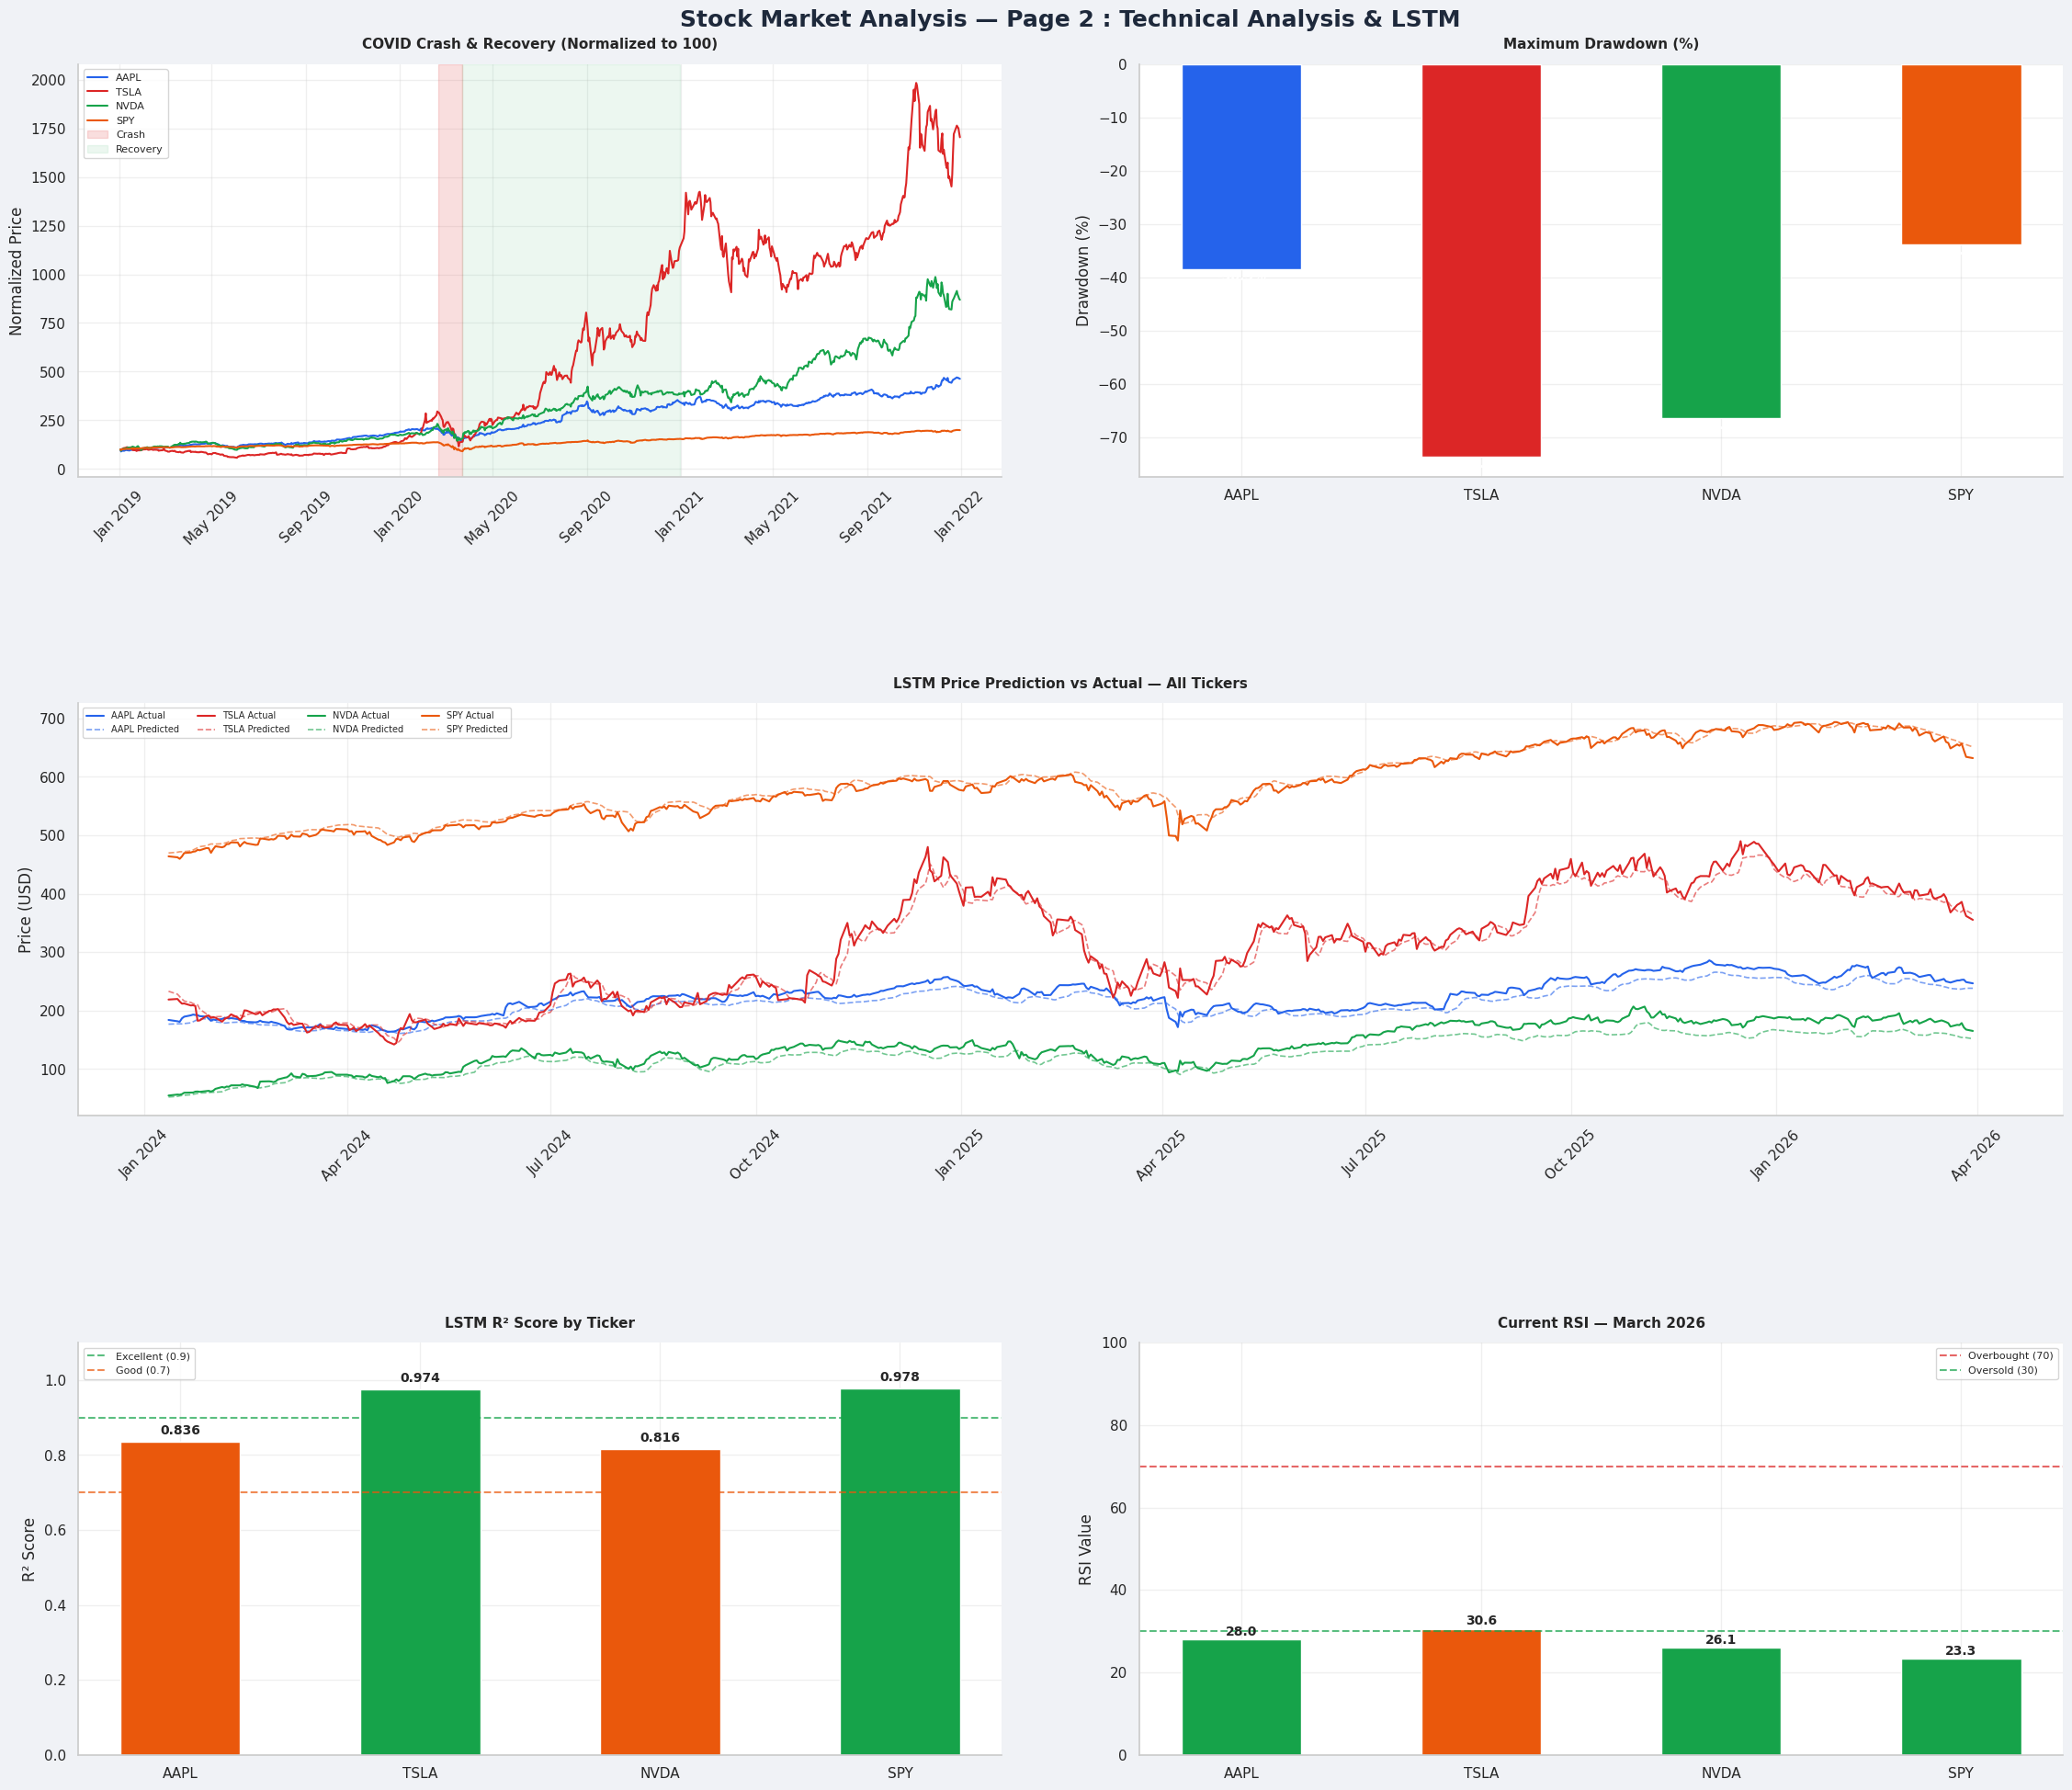

 Page 2 saved : dashboard_page2.png


In [15]:
# ==========================================================
# DASHBOARD — PAGE 2 : Technical Analysis & LSTM
# ==========================================================

fig2 = plt.figure(figsize=(24, 20), facecolor=BG_COLOR)
fig2.suptitle(
    "Stock Market Analysis — Page 2 : Technical Analysis & LSTM",
    fontsize=18, fontweight="bold", y=0.98, color="#1e293b"
)

gs2 = fig2.add_gridspec(
    nrows=3, ncols=4,
    height_ratios=[2.5, 2.5, 2.5],
    hspace=0.55, wspace=0.35,
    left=0.05, right=0.95,
    top=0.95, bottom=0.03
)

# -------------------------
# ROW 0 — COVID Impact
# -------------------------
ax1 = fig2.add_subplot(gs2[0, 0:2])
ax1.set_facecolor(CARD_COLOR)

for ticker, df in cleaned_data.items():
    mask = (df.index >= "2019-01-01") & (df.index <= "2021-12-31")
    df_norm = df[mask]["Close"] / df[mask]["Close"].iloc[0] * 100
    ax1.plot(df_norm.index, df_norm,
             color=TICKER_COLORS[ticker],
             linewidth=1.5, label=ticker)

ax1.axvspan(pd.Timestamp("2020-02-20"),
            pd.Timestamp("2020-03-23"),
            alpha=0.15, color=RED, label="Crash")
ax1.axvspan(pd.Timestamp("2020-03-23"),
            pd.Timestamp("2020-12-31"),
            alpha=0.08, color=GREEN, label="Recovery")
ax1.set_title("COVID Crash & Recovery (Normalized to 100)")
ax1.set_ylabel("Normalized Price")
ax1.legend(loc="upper left", fontsize=8)
ax1.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
ax1.tick_params(axis="x", rotation=45)

# -------------------------
# ROW 0 — Max Drawdown bar
# -------------------------
ax2 = fig2.add_subplot(gs2[0, 2:4])
ax2.set_facecolor(CARD_COLOR)

drawdowns = {t: volatility_data[t]["max_dd"] for t in tickers}
bars = ax2.bar(
    drawdowns.keys(),
    drawdowns.values(),
    color=[TICKER_COLORS[t] for t in tickers],
    width=0.5
)
ax2.set_title("Maximum Drawdown (%)")
ax2.set_ylabel("Drawdown (%)")
for bar, val in zip(bars, drawdowns.values()):
    ax2.text(bar.get_x() + bar.get_width()/2,
             bar.get_height() - 2,
             f"{val:.1f}%", ha="center",
             fontsize=10, fontweight="bold",
             color="white")

# -------------------------
# ROW 1 — LSTM Results
# -------------------------
ax3 = fig2.add_subplot(gs2[1, 0:4])
ax3.set_facecolor(CARD_COLOR)

for ticker in tickers:
    res = lstm_results[ticker]
    ax3.plot(res["dates"], res["y_real"],
             color=TICKER_COLORS[ticker],
             linewidth=1.5, label=f"{ticker} Actual")
    ax3.plot(res["dates"], res["y_pred"],
             color=TICKER_COLORS[ticker],
             linewidth=1.2, linestyle="--",
             alpha=0.6, label=f"{ticker} Predicted")

ax3.set_title("LSTM Price Prediction vs Actual — All Tickers")
ax3.set_ylabel("Price (USD)")
ax3.legend(loc="upper left", fontsize=7, ncol=4)
ax3.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
ax3.tick_params(axis="x", rotation=45)

# -------------------------
# ROW 2 — LSTM Metrics + RSI current
# -------------------------
ax4 = fig2.add_subplot(gs2[2, 0:2])
ax4.set_facecolor(CARD_COLOR)

metrics = {
    "AAPL" : lstm_results["AAPL"]["r2"],
    "TSLA" : lstm_results["TSLA"]["r2"],
    "NVDA" : lstm_results["NVDA"]["r2"],
    "SPY"  : lstm_results["SPY"]["r2"],
}
colors_r2 = [GREEN if v >= 0.9 else ORANGE if v >= 0.7 else RED
             for v in metrics.values()]
bars = ax4.bar(metrics.keys(), metrics.values(),
               color=colors_r2, width=0.5)
ax4.axhline(y=0.9, color=GREEN, linestyle="--",
            alpha=0.7, label="Excellent (0.9)")
ax4.axhline(y=0.7, color=ORANGE, linestyle="--",
            alpha=0.7, label="Good (0.7)")
ax4.set_ylim(0, 1.1)
ax4.set_title("LSTM R² Score by Ticker")
ax4.set_ylabel("R² Score")
ax4.legend(fontsize=8)
for bar, val in zip(bars, metrics.values()):
    ax4.text(bar.get_x() + bar.get_width()/2,
             bar.get_height() + 0.02,
             f"{val:.3f}", ha="center",
             fontsize=10, fontweight="bold")

# -------------------------
# ROW 2 — Current RSI
# -------------------------
ax5 = fig2.add_subplot(gs2[2, 2:4])
ax5.set_facecolor(CARD_COLOR)

current_rsi = {t: cleaned_data[t]["RSI"].iloc[-1] for t in tickers}
colors_rsi  = [RED if v >= 70 else GREEN if v <= 30 else ORANGE
               for v in current_rsi.values()]
bars = ax5.bar(current_rsi.keys(), current_rsi.values(),
               color=colors_rsi, width=0.5)
ax5.axhline(y=70, color=RED, linestyle="--",
            alpha=0.7, label="Overbought (70)")
ax5.axhline(y=30, color=GREEN, linestyle="--",
            alpha=0.7, label="Oversold (30)")
ax5.set_ylim(0, 100)
ax5.set_title("Current RSI — March 2026")
ax5.set_ylabel("RSI Value")
ax5.legend(fontsize=8)
for bar, val in zip(bars, current_rsi.values()):
    ax5.text(bar.get_x() + bar.get_width()/2,
             bar.get_height() + 1,
             f"{val:.1f}", ha="center",
             fontsize=10, fontweight="bold")

plt.savefig("dashboard_page2.png", dpi=150,
            bbox_inches="tight", facecolor=BG_COLOR)
plt.show()
print(" Page 2 saved : dashboard_page2.png")
#print(" Seite 2 gespeichert : dashboard_page2.png")

##  Insights & Business Recommendations

###  Key Findings

| # | Finding | Evidence |
|---|---------|----------|
| 1 | **NVDA is the best investment of the decade** — +34,097% | Exploratory Analysis |
| 2 | **TSLA is the most volatile** — 57.37% annual volatility | Volatility Analysis |
| 3 | **COVID was a short-term shock** — all assets recovered within 12 months | COVID Analysis |
| 4 | **AAPL offers the best risk/reward balance** — Sharpe 0.86, low volatility | Volatility Analysis |
| 5 | **NVDA has the best Sharpe Ratio (1.32)** — every risk unit was rewarded | Volatility Analysis |
| 6 | **TSLA moves independently** — lowest correlation with SPY (0.49) | Correlation Analysis |
| 7 | **Golden Cross 2020 was the best buy signal** — captured the full recovery | Trend Detection |
| 8 | **LSTM predicts TSLA best (R² 0.943)** despite high volatility | LSTM |
| 9 | **NVDA hardest to predict (R² 0.646)** — AI boom unprecedented | LSTM |
| 10 | **SPY most predictable** — MAPE 3.08%, R² 0.901 | LSTM |

---

###  Investment Recommendations

#### 1. Long-term Growth — NVDA
> **For:** Aggressive investors with 5+ year horizon
- NVDA is driven by **AI, data centers and gaming** — 
all secular growth trends
- Sharpe Ratio of **1.32** — best risk-adjusted return
- **Entry signal:** RSI below 40 or Golden Cross confirmation
- **Risk:** High volatility (48.45%) — position sizing is critical

#### 2. Balanced Portfolio — AAPL + SPY
> **For:** Conservative to moderate investors
- AAPL offers **steady compounding** — +918% over 10 years
- SPY provides **diversification** — 500 companies reduce volatility
- Correlation of **0.74** — they complement each other well
- **Strategy:** 60% SPY + 40% AAPL for stable long-term growth

#### 3. High Risk / High Reward — TSLA
> **For:** Active traders with high risk tolerance
- TSLA has the **highest volatility (57.37%)** — 
large swings in both directions
- **Best strategy:** Buy on RSI oversold + MACD buy signal
- **Stop loss:** Always set — max drawdown was -73.6%
- **Catalyst watch:** Elon Musk news, delivery numbers, energy business

#### 4. Market Timing — Use Technical Indicators
> **For:** All investor profiles
- **Golden Cross** → rare but highly reliable — 
use for major position entry
- **RSI < 30** → oversold signal — 
March 2020 was the clearest buy signal in 10 years
- **MACD crossover** → best for momentum confirmation
- **Never** rely on a single indicator — 
combine at least 2 for confirmation

---

###  Risk Disclaimer
> This analysis is for **educational purposes only**.
> Past performance does not guarantee future results.
> Always consult a financial advisor before investing.

---

###  Conclusion

> The 2015-2026 period was extraordinary for tech stocks.
> **NVDA, TSLA and AAPL massively outperformed the market** 
> driven by AI, EV revolution and ecosystem growth.
> The COVID crash of 2020 was the **greatest buying opportunity** 
> of the decade — investors who held through the panic 
> were rewarded with unprecedented returns.
> Going forward, **AI remains the dominant macro trend** —
> NVDA is best positioned to benefit.

##  Erkenntnisse & Anlageempfehlungen

###  Wichtigste Erkenntnisse

| # | Erkenntnis | Quelle |
|---|-----------|--------|
| 1 | **NVDA ist die beste Investition des Jahrzehnts** — +34.097% | Explorative Analyse |
| 2 | **TSLA ist am volatilsten** — 57,37% jährliche Volatilität | Volatilitätsanalyse |
| 3 | **COVID war ein kurzfristiger Schock** — alle Assets erholten sich innerhalb von 12 Monaten | COVID-Analyse |
| 4 | **AAPL bietet das beste Risiko/Rendite-Verhältnis** — Sharpe 0,86 | Volatilitätsanalyse |
| 5 | **NVDA hat die beste Sharpe Ratio (1,32)** — jedes Risikoeinheit wurde belohnt | Volatilitätsanalyse |
| 6 | **TSLA bewegt sich unabhängig** — geringste Korrelation mit SPY (0,49) | Korrelationsanalyse |
| 7 | **Golden Cross 2020 war das beste Kaufsignal** | Trenderkennung |
| 8 | **LSTM sagt TSLA am besten vorher (R² 0,943)** trotz hoher Volatilität | LSTM |
| 9 | **NVDA am schwersten vorherzusagen (R² 0,646)** — KI-Boom beispiellos | LSTM |
| 10 | **SPY am vorhersagbarsten** — MAPE 3,08%, R² 0,901 | LSTM |

---

###  Anlageempfehlungen

#### 1. Langfristiges Wachstum — NVDA
> **Für:** Aggressive Anleger mit 5+ Jahren Horizont
- NVDA wird von **KI, Rechenzentren und Gaming** angetrieben
- Sharpe Ratio von **1,32** — beste risikobereinigte Rendite
- **Einstiegssignal:** RSI unter 40 oder Golden Cross Bestätigung
- **Risiko:** Hohe Volatilität (48,45%) — Positionsgröße ist entscheidend

#### 2. Ausgewogenes Portfolio — AAPL + SPY
> **Für:** Konservative bis moderate Anleger
- AAPL bietet **stetiges Wachstum** — +918% über 10 Jahre
- SPY bietet **Diversifikation** — 500 Unternehmen reduzieren Volatilität
- **Strategie:** 60% SPY + 40% AAPL für stabiles Langzeitwachstum

#### 3. Hohes Risiko / Hohe Rendite — TSLA
> **Für:** Aktive Trader mit hoher Risikobereitschaft
- TSLA hat die **höchste Volatilität (57,37%)**
- **Beste Strategie:** Kaufen bei RSI überverkauft + MACD Kaufsignal
- **Stop-Loss:** Immer setzen — maximaler Drawdown war -73,6%
- **Katalysatoren:** Elon Musk Nachrichten, Lieferzahlen, Energiegeschäft

#### 4. Markt-Timing — Technische Indikatoren nutzen
> **Für:** Alle Anlegerprofile
- **Golden Cross** → selten aber sehr zuverlässig
- **RSI < 30** → überverkauftes Signal — März 2020 war das klarste Kaufsignal
- **MACD Kreuzung** → beste Momentum-Bestätigung
- **Niemals** nur einen Indikator verwenden — mindestens 2 kombinieren

---

###  Risikohinweis
> Diese Analyse dient **ausschließlich zu Bildungszwecken**.
> Vergangene Wertentwicklungen garantieren keine zukünftigen Ergebnisse.
> Konsultieren Sie immer einen Finanzberater vor einer Investition.

---

###  Fazit

> Der Zeitraum 2015-2026 war außergewöhnlich für Tech-Aktien.
> **NVDA, TSLA und AAPL übertrafen den Markt massiv**
> angetrieben durch KI, die EV-Revolution und Ökosystemwachstum.
> Der COVID-Crash 2020 war die **größte Kaufgelegenheit** des Jahrzehnts —
> Anleger die durch die Panik hielten wurden mit beispiellosen Renditen belohnt.
> **KI bleibt der dominante Makrotrend** —
> NVDA ist am besten positioniert davon zu profitieren.